
# IA nas engenharias: minicurso prático em Python
### Machine Learning para Civil, Produção, Elétrica, Mecânica e Química

**Ministrante:** Dra. Patricia Pedroso Estevam Ribeiro · Google Colab · não é preciso instalar nada nem baixar dados (todos os dados são **simulados** dentro do notebook).

**Para quem é:** quem **nunca programou** também consegue acompanhar. Você não precisa escrever código: precisa **executar** as células, **ler os comentários** e **interpretar os resultados**. Os comentários explicam o que cada linha faz.

O notebook **segue a mesma ordem da palestra e da apostila**. Cada exemplo ou exercício tem uma *ficha* (problema, dados, modelo, métrica, o que observar) e indica **em quais slides** e **em qual seção da apostila** está a explicação e o mesmo código. Organização: **Parte A = Exemplos 1 a 5**; **Blocos 1 a 5 = uma engenharia cada, com Exercícios 1.1, 1.2, ...**

| Parte | Conteúdo | Apostila |
|---|---|---|
| **Parte 0** | Preparação: como o Colab funciona, Python em 5 minutos, bibliotecas | cap. 2 e 12 |
| **Parte A** | **Exemplos 1 a 5** (conceitos): fronteira, árvore e Random Forest, regressão, SVM, overfitting | cap. 3 e 4 |
| **Bloco 1** | **Civil**: prever a resistência do concreto (regressão) | cap. 5 |
| **Bloco 2** | **Produção**: peça boa ou defeituosa (classificação, métricas e curva ROC) | cap. 6 e 4.2 |
| **Bloco 3** | **Elétrica**: perfis e anomalias em motores (k-means, hierárquico, Isolation Forest) | cap. 7 e 4.4 |
| **Bloco 4** | **Mecânica**: condição de rolamentos (PCA + SVM) | cap. 8 e 4.5 |
| **Bloco 5** | **Química**: concentração por espectros (PCA + regressão) | cap. 9 |
| **Fechamento** | Fechamento: resumo e desafio | cap. 10 |
| **Bônus A** | *Extra*: imagens de folhas e Teachable Machine | cap. 13 |
| **Bônus B** | *Extra*: alerta enviado ao n8n | cap. 14 |
| **Bônus C** | *Extra*: rede neural (primeiro passo do Deep Learning) | cap. 3 |

> **Como usar:** execute as células em ordem, de cima para baixo (**Shift+Enter**). Altere **um valor por vez** e observe o que muda. Se aparecer um erro como `name '...' is not defined`, execute as células anteriores (menu **Ambiente de execução › Executar tudo**).



---
## Parte 0. Preparação

### 0.1 Como o Colab funciona (leia uma vez)
- O notebook é feito de **células**. Células de **texto** (como esta) explicam; células de **código** (com um botão ▶ à esquerda) executam.
- Para executar uma célula: clique nela e aperte **Shift+Enter** (ou clique no ▶). O resultado aparece **logo abaixo**.
- O código roda em um computador do Google, na nuvem. Nada é instalado no seu computador.
- **Tudo que começa com `#` é comentário**: o Python ignora, é só explicação para você.
- Ao abrir o notebook, use **Arquivo › Salvar uma cópia no Drive**: assim você pode editar sem perder o original.

### Python em 5 minutos: as 5 ideias que aparecem no curso
| Ideia | Exemplo | Para que serve |
|---|---|---|
| **Variável** | `idade = 28` | guardar um valor com um nome |
| **Lista / vetor** | `idades = [3, 7, 28]` | guardar vários valores |
| **Função** | `np.mean(idades)` | uma "máquina" que recebe dados e devolve um resultado |
| **Tabela (DataFrame)** | `pd.DataFrame(...)` | dados em linhas (amostras) e colunas (variáveis) |
| **Gráfico** | `plt.plot(...)`, `plt.show()` | desenhar os dados |


Resistência média: 23.0 MPa
   idade_dias  resistencia_MPa
0           3             14.0
1           7             22.5
2          28             32.5


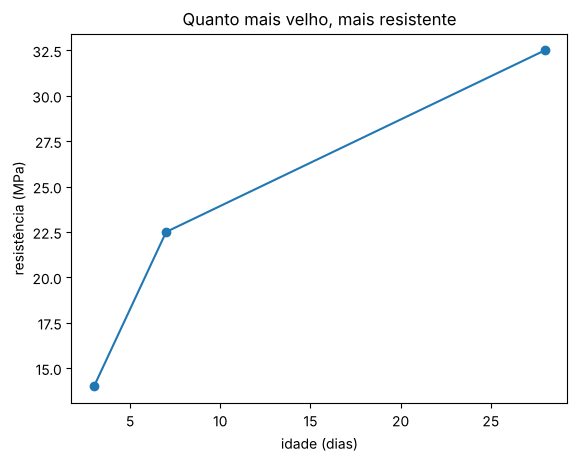

In [1]:

# Exemplo mínimo: execute e veja o resultado. Nada aqui é "machine learning" ainda.
import numpy as np                 # numpy: contas com vetores e números
import pandas as pd                # pandas: tabelas de dados
import matplotlib.pyplot as plt    # matplotlib: gráficos

idades = [3, 7, 28]                # 1) uma lista com as idades do concreto (dias)
resistencia = [14.0, 22.5, 32.5]   # 2) uma lista com a resistência medida (MPa)

media = np.mean(resistencia)       # 3) função do numpy: calcula a média da lista
print("Resistência média: %.1f MPa" % media)   # 4) print escreve o resultado na tela

tabela = pd.DataFrame({"idade_dias": idades, "resistencia_MPa": resistencia})   # 5) monta uma tabela
print(tabela)                      # cada linha é uma amostra; cada coluna é uma variável

plt.plot(tabela["idade_dias"], tabela["resistencia_MPa"], "o-")   # 6) gráfico: x = idade, y = resistência
plt.xlabel("idade (dias)"); plt.ylabel("resistência (MPa)")       # nomes dos eixos
plt.title("Quanto mais velho, mais resistente"); plt.show()       # título e exibição



### A receita que se repete em todo exercício
1. **Dados**: uma tabela com as variáveis de entrada (**X**) e, se houver, o que queremos prever (**y**).
2. **Separar treino e teste**: o modelo **aprende no treino** e é **avaliado no teste** (dados que ele nunca viu). Função `train_test_split`.
3. **Escolher o modelo**: um objeto como `LinearRegression()` ou `RandomForestClassifier()`.
4. **Treinar**: `modelo.fit(X_treino, y_treino)` ("ajuste o modelo aos exemplos").
5. **Prever**: `modelo.predict(X_teste)` ("dê a resposta para dados novos").
6. **Medir**: comparar o previsto com o real (MAE, acurácia, sensibilidade...).

### 0.2 Instalação de pacotes (opcional)
**No Colab você não precisa instalar nada**: as bibliotecas já vêm prontas. Se for rodar **fora do Colab** (Jupyter ou VS Code no seu computador), tire o `#` da linha abaixo e execute **uma vez**. Quem usa o Colab pode pular esta célula.


In [2]:

# Só para quem NÃO usa o Colab. No Colab, pule esta célula.
# Para instalar, apague o "#" do início da próxima linha e execute (depois reinicie o ambiente):
# %pip install numpy pandas matplotlib seaborn scikit-learn scipy scikit-image requests



### 0.3 Carregar as bibliotecas e as funções de apoio
Uma **biblioteca** é um conjunto de funções prontas. Usamos:

| Biblioteca | Para que serve neste curso |
|---|---|
| `numpy` | números e sorteios aleatórios (simular dados) |
| `pandas` | tabelas de dados |
| `matplotlib` e `seaborn` | gráficos |
| `scikit-learn` (`sklearn`) | **os modelos de machine learning** e as métricas |
| `scipy` | o dendrograma (agrupamento hierárquico) |

A célula abaixo só **carrega** as bibliotecas e define cores e duas funções de apoio (`limpa` e `matriz`). Ela não mostra gráficos: ao final escreve *Ambiente pronto!*.


In [3]:

# ---------- Bibliotecas básicas ----------
import numpy as np                      # contas e números aleatórios
import pandas as pd                     # tabelas (DataFrame)
import matplotlib.pyplot as plt         # gráficos
import seaborn as sns                   # gráficos estatísticos mais bonitos

# ---------- Ferramentas do scikit-learn (os "modelos") ----------
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold  # separar treino/teste e validação cruzada
from sklearn.preprocessing import StandardScaler, PolynomialFeatures   # padronizar variáveis; criar termos polinomiais
from sklearn.pipeline import make_pipeline                              # encadear etapas (ex.: padronizar e depois modelar)
from sklearn.linear_model import LinearRegression, LogisticRegression   # modelos lineares
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, IsolationForest   # florestas de árvores
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree                       # árvore de decisão
from sklearn.svm import SVC                                             # SVM (máquina de vetores de suporte)
from sklearn.cluster import KMeans                                      # agrupamento k-means
from sklearn.decomposition import PCA                                   # análise de componentes principais
from sklearn.metrics import (mean_absolute_error, r2_score, accuracy_score, recall_score,
                             precision_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             adjusted_rand_score, silhouette_score, roc_curve, roc_auc_score)  # métricas
from scipy.cluster.hierarchy import linkage, dendrogram                 # agrupamento hierárquico

# ---------- Configurações ----------
SEED = 42                               # "semente" do sorteio: com ela fixa, todos obtêm os mesmos resultados
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")    # estilo dos gráficos
plt.rcParams["figure.dpi"] = 100                        # resolução dos gráficos
TEAL, ORANGE, NAVY, RED = "#1F8A8A", "#F2A93B", "#0F2B3D", "#E4572E"   # cores usadas nos gráficos

# ---------- Funções de apoio (definidas aqui para usar várias vezes) ----------
def limpa(ax):
    """Remove as bordas de cima e da direita de um gráfico (visual mais limpo)."""
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

def matriz(y_real, y_prev, ax, rotulos, nomes=None, cmap="Blues", titulo=None):
    """Desenha a matriz de confusão (linhas = real, colunas = previsto)."""
    ConfusionMatrixDisplay.from_predictions(y_real, y_prev, labels=rotulos, display_labels=nomes or rotulos,
                                            cmap=cmap, colorbar=False, ax=ax)
    ax.set_xlabel("previsto"); ax.set_ylabel("real"); ax.grid(False)
    if titulo:
        ax.set_title(titulo)

print("Ambiente pronto!")


Ambiente pronto!



---
## Parte A · Exemplos 1 a 5: os conceitos (slides 33 a 44)
Antes das cinco engenharias, cinco ideias que se repetem em todas elas. Usamos **motores elétricos** como exemplo. Cada ideia é um exemplo curto: **Exemplo 1** a **Exemplo 5**. Depois vêm os **Blocos 1 a 5** (um por engenharia, slides 51 a 60), com exercícios numerados (1.1, 1.2, ...).



### Exemplo 1 · Aprendizado supervisionado: aprender uma fronteira
| | |
|---|---|
| **Problema** | Classificar um motor como **normal** ou **com falha** a partir de vibração e temperatura, e dizer a probabilidade de falha de uma **máquina nova**. |
| **Dados** | 100 motores simulados já classificados (60 normais e 40 com falha), com vibração (mm/s) e temperatura (°C). |
| **Modelo / técnica** | **Regressão logística** (estima a probabilidade de falha com uma curva em S; a fronteira é uma reta). |
| **Como medimos** | Probabilidade de falha da máquina nova (0 a 100%). |
| **O que observar** | A linha tracejada é a fronteira aprendida. A estrela fica perto dela: o modelo não tem certeza (cerca de 65% de falha). |
| **Nos slides** | 33 e 34 |
| **Na apostila** | seção 3.5 e figura 1 |


Probabilidade de falha da máquina nova: 64%

log-odds de falha = α + β1·vibração + β2·temperatura   (variáveis padronizadas)
α = -1.01 | β (vibração) = 1.83 | β (temperatura) = 2.35
β > 0: quanto maior a variável, maior a chance de falha.

Como ler os pesos (β):
  Vibração:    +1 desvio-padrão (1.5 mm/s) aumenta o log-odds de falha em 1.83  -> chances (odds) x 6.2
  Temperatura: +1 desvio-padrão (13.4 °C) aumenta o log-odds de falha em 2.35  -> chances (odds) x 10.5
  A variável de maior peso é a temperatura (2.35 contra 1.83): ela puxa mais a decisão do modelo.
  α = -1.01 é o log-odds de uma máquina na média das duas variáveis (probabilidade 27%).

No teste (30 motores): acurácia = 1.00 | precisão = 1.00 | sensibilidade = 1.00 | F1 = 1.00
Matriz de confusão: VN = 18 (normal certo) | FP = 0 | FN = 0 | VP = 12 (falha certa)


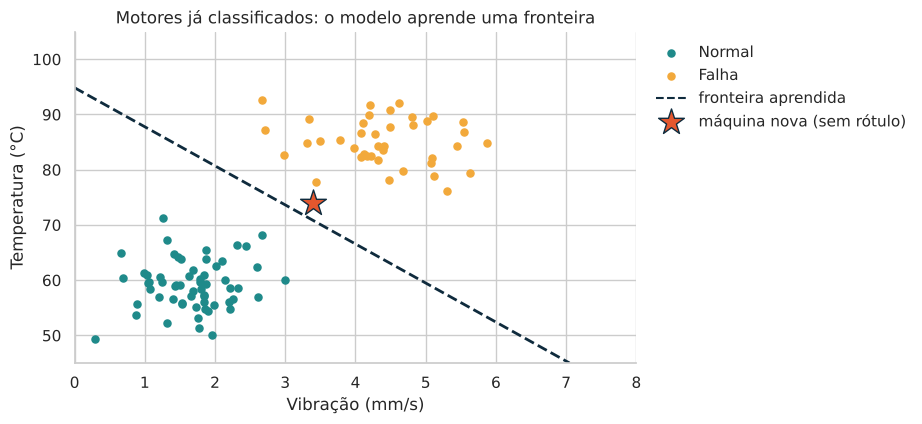

In [4]:

# --- 1) Criar os dados (simulados) ---
rng = np.random.default_rng(7)                                      # gerador de números aleatórios (semente 7)
vib = np.r_[rng.normal(1.8, 0.6, 60), rng.normal(4.5, 0.9, 40)]     # vibração: 60 normais (média 1,8) + 40 com falha (média 4,5)
temp = np.r_[rng.normal(60, 5, 60), rng.normal(85, 5, 40)]          # temperatura: normais ~60 °C, com falha ~85 °C
rotulo = np.r_[np.zeros(60), np.ones(40)]                           # rótulo: 0 = normal, 1 = falha

# --- 2) Treinar o modelo ---
X = np.c_[vib, temp]                                                # junta as duas variáveis em uma tabela X
modelo = make_pipeline(StandardScaler(), LogisticRegression())      # padroniza as variáveis e aplica a regressão logística
modelo.fit(X, rotulo)                                               # TREINAR: o modelo aprende a fronteira com os exemplos

# --- 3) Usar o modelo em uma máquina nova (sem rótulo) ---
nova = np.array([[3.4, 74.0]])                                      # vibração 3,4 mm/s e temperatura 74 °C
p_falha = modelo.predict_proba(nova)[0, 1]                          # probabilidade de ser da classe 1 (falha)
print("Probabilidade de falha da máquina nova: %.0f%%" % (100 * p_falha))

# --- 2b) Olhar o que o modelo aprendeu: α (intercepto) e β (pesos) da regressão logística ---
lr = modelo[-1]                                                     # o passo final do pipeline: a regressão logística
print("\nlog-odds de falha = α + β1·vibração + β2·temperatura   (variáveis padronizadas)")
print("α = %.2f | β (vibração) = %.2f | β (temperatura) = %.2f" % (lr.intercept_[0], lr.coef_[0][0], lr.coef_[0][1]))
print("β > 0: quanto maior a variável, maior a chance de falha.")
dp = modelo[0].scale_                                               # desvio-padrão de cada variável (a padronização divide por ele)
b = lr.coef_[0]                                                     # os dois pesos β
print("\nComo ler os pesos (β):")
print("  Vibração:    +1 desvio-padrão (%.1f mm/s) aumenta o log-odds de falha em %.2f  -> chances (odds) x %.1f" % (dp[0], b[0], np.exp(b[0])))
print("  Temperatura: +1 desvio-padrão (%.1f °C) aumenta o log-odds de falha em %.2f  -> chances (odds) x %.1f" % (dp[1], b[1], np.exp(b[1])))
print("  A variável de maior peso é a %s (%.2f contra %.2f): ela puxa mais a decisão do modelo." % (
      "temperatura" if b[1] > b[0] else "vibração", max(b), min(b)))
print("  α = %.2f é o log-odds de uma máquina na média das duas variáveis (probabilidade %.0f%%)." % (lr.intercept_[0], 100 / (1 + np.exp(-lr.intercept_[0]))))

# --- 2c) Avaliar com dados que o modelo não viu: separa 70% treino e 30% teste só para MEDIR ---
X_a, X_b, y_a, y_b = train_test_split(X, rotulo, test_size=0.3, stratify=rotulo, random_state=SEED)
m_av = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_a, y_a)
pred_b = m_av.predict(X_b)                                          # classe prevista (0 = normal, 1 = falha) no teste
vn_, fp_, fn_, vp_ = confusion_matrix(y_b, pred_b).ravel()
print("\nNo teste (%d motores): acurácia = %.2f | precisão = %.2f | sensibilidade = %.2f | F1 = %.2f" % (
      len(y_b), accuracy_score(y_b, pred_b), precision_score(y_b, pred_b), recall_score(y_b, pred_b), f1_score(y_b, pred_b)))
print("Matriz de confusão: VN = %d (normal certo) | FP = %d | FN = %d | VP = %d (falha certa)" % (vn_, fp_, fn_, vp_))

# --- 4) Desenhar: pontos, fronteira e a máquina nova ---
xx, yy = np.meshgrid(np.linspace(0, 8, 300), np.linspace(45, 105, 300))     # grade de pontos para colorir o plano
zz = modelo.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)   # probabilidade em cada ponto da grade
fig, ax = plt.subplots(figsize=(9.4, 4.4))
ax.scatter(vib[rotulo == 0], temp[rotulo == 0], color=TEAL, s=26, label="Normal")   # motores normais
ax.scatter(vib[rotulo == 1], temp[rotulo == 1], color=ORANGE, s=26, label="Falha")  # motores com falha
ax.contour(xx, yy, zz, levels=[0.5], colors=NAVY, linestyles="--", linewidths=2)    # fronteira: onde a probabilidade é 50%
ax.plot([], [], "--", color=NAVY, label="fronteira aprendida")                      # entrada da legenda
ax.scatter(*nova[0], marker="*", s=380, color=RED, edgecolor=NAVY, zorder=5, label="máquina nova (sem rótulo)")
ax.set_xlabel("Vibração (mm/s)"); ax.set_ylabel("Temperatura (°C)"); ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1)); limpa(ax)   # legenda fora do gráfico
ax.set_title("Motores já classificados: o modelo aprende uma fronteira"); plt.tight_layout(); plt.show()


**Leitura do gráfico** (leia antes das perguntas)

- **O que cada ponto é:** um motor já inspecionado. **Eixo horizontal:** vibração (mm/s). **Eixo vertical:** temperatura (°C). **Verde:** motor normal. **Laranja:** motor que falhou.
- **O que os pontos mostram:** os motores com falha têm vibração **e** temperatura mais altas, no canto superior direito. Os normais ficam no canto inferior esquerdo. Quando a vibração sobe, a temperatura também sobe, o que faz sentido para um motor com defeito.
- **O que a reta tracejada é:** a **fronteira de decisão**, não uma tendência dos dados. Ela precisa passar entre os dois grupos e, como eles estão em diagonal, a fronteira cai de cima à esquerda para baixo à direita. Essa inclinação negativa vem só da posição dos grupos: **a reta não diz que mais temperatura significa menos vibração**.
- **Como ler:** tudo acima e à direita da reta é classificado como **Falha**, e tudo abaixo e à esquerda como **Normal**. A **estrela** (máquina nova, vibração ≈ 3,4 e temperatura ≈ 74 °C) cai um pouco acima da reta, então o modelo diz Falha, mas com pouca folga. Isso bate com a probabilidade de cerca de 64% impressa acima.
- **Os pesos β (impressos acima):** com as variáveis padronizadas, um aumento de **1 desvio-padrão** na vibração soma **1,83** ao log-odds de falha, e na temperatura soma **2,35**. Os dois são positivos (mais vibração ou mais temperatura, mais chance de falha) e a **temperatura pesa mais**. Em chances (odds), isso multiplica a chance de falha por cerca de **6** (vibração) e **10** (temperatura).
- **Na engenharia:** o modelo transforma duas leituras de sensor em um número (a probabilidade de falha) que ajuda a decidir se a máquina deve ser inspecionada.


**Perguntas**
1. Onde está a "aprendizagem"? (os rótulos vieram de especialistas: o modelo só generaliza o que já foi classificado)
2. A máquina nova fica perto da fronteira. O que significa uma probabilidade de falha de cerca de 65%? Você manda inspecionar?
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** A aprendizagem está em **ajustar α e os β** (pesos) aos exemplos já rotulados, até a fronteira separar bem normais e falhas. O modelo não "entende" o motor: só generaliza o padrão dos rótulos que especialistas deram. **Sem rótulos confiáveis não há aprendizado supervisionado.**

**2.** Cerca de 65% de falha quer dizer que, entre motores com esses valores, aproximadamente 2 em cada 3 falhariam. É uma zona de **incerteza** (perto da fronteira), não de certeza. Se uma falha inesperada custa muito mais do que uma inspeção, vale **inspecionar**. O modelo informa o risco; **quem decide é a pessoa**, pelo custo de cada erro.

*Sobre a métrica:* no teste, as classes aqui são bem separadas, por isso acurácia, precisão e sensibilidade chegam a 1,00. Em dados reais isso quase nunca acontece.

</details>



### Exemplo 2 · Árvore de decisão e Random Forest
| | |
|---|---|
| **Problema** | Separar a região de operação **normal** da que precisa de **inspeção**, usando vibração e temperatura. |
| **Dados** | 400 pontos simulados; a região normal é uma faixa (vibração 1 a 6,5 e temperatura 65 a 92), com 8% de rótulos trocados (ruído). |
| **Modelo / técnica** | **Árvore de decisão** (perguntas do tipo "vibração > 6?") x **Random Forest** (200 árvores, cada uma com uma amostra diferente, que votam). |
| **Como medimos** | Acurácia no teste (fração de acertos em dados novos). |
| **O que observar** | Cada árvore tem fronteiras recortadas e diferentes. A votação da floresta é mais estável e acerta mais (cerca de 82% contra 86%). |
| **Nos slides** | 35 a 38 |
| **Na apostila** | seção 4.2 e figura 3 |


,Acurácia,Precisão,Sensibilidade,F1
Modelo,,,,
Árvore de decisão,0.825,0.855,0.887,0.87
Random Forest,0.862,0.868,0.934,0.90


Acurácia no teste | árvore: 82.5% | Random Forest: 86.2%


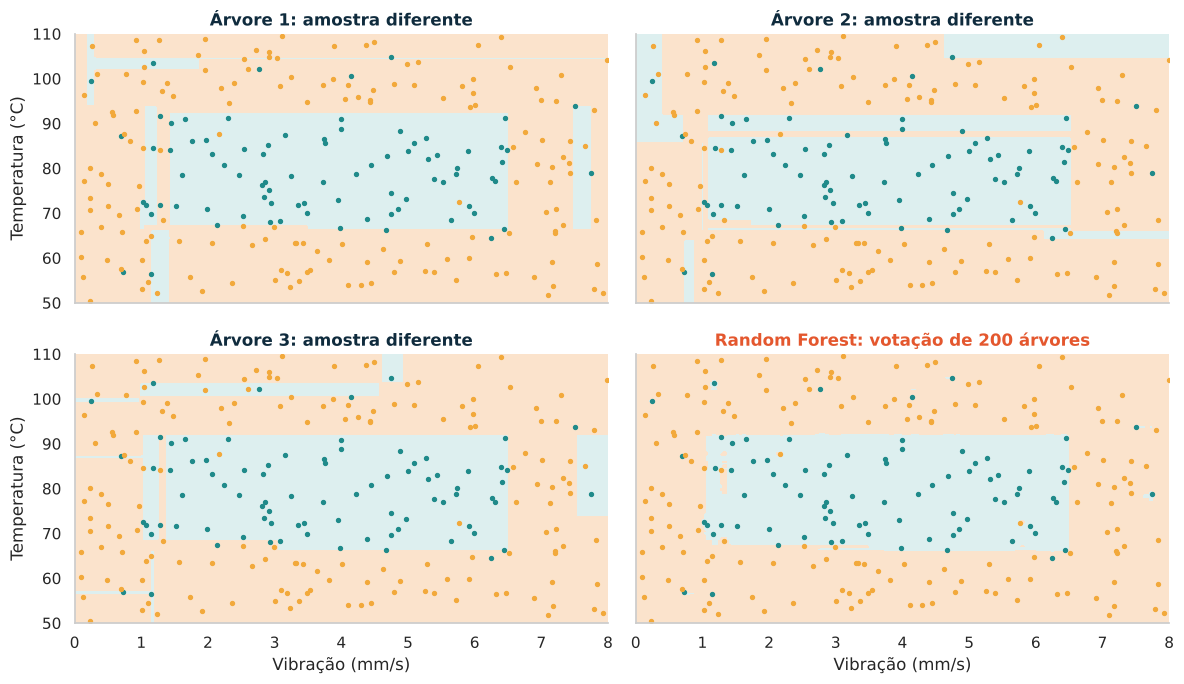

In [5]:

# --- 1) Criar os dados ---
rng = np.random.default_rng(11)
n = 400                                                         # número de pontos
v = rng.uniform(0, 8, n)                                        # vibração sorteada entre 0 e 8 mm/s
t = rng.uniform(50, 110, n)                                     # temperatura sorteada entre 50 e 110 °C
faixa_ok = (v > 1) & (v < 6.5) & (t > 65) & (t < 92)            # True se o motor está na faixa normal de operação
erro_rotulo = rng.random(n) < 0.08                              # 8% dos rótulos serão trocados (ruído real)
y_c = np.where(faixa_ok ^ erro_rotulo, 0, 1)                    # 0 = normal, 1 = inspecionar
X_c = np.c_[v, t]                                               # tabela de entrada (vibração, temperatura)

# --- 2) Separar treino (60%) e teste (40%) ---
Xa, Xb, ya, yb = train_test_split(X_c, y_c, test_size=0.4, random_state=11)

# --- 3) Treinar e comparar os dois modelos ---
arvore_c = DecisionTreeClassifier(random_state=11).fit(Xa, ya)                       # uma única árvore
floresta_c = RandomForestClassifier(n_estimators=200, random_state=11).fit(Xa, ya)   # 200 árvores que votam
met = []
for nome_m, mod_m in [("Árvore de decisão", arvore_c), ("Random Forest", floresta_c)]:
    pr = mod_m.predict(Xb)                                                           # classe prevista no teste
    met.append({"Modelo": nome_m, "Acurácia": accuracy_score(yb, pr), "Precisão": precision_score(yb, pr),
                "Sensibilidade": recall_score(yb, pr), "F1": f1_score(yb, pr)})      # 4 métricas de classificação
display(pd.DataFrame(met).set_index("Modelo").round(3))
print("Acurácia no teste | árvore: %.1f%% | Random Forest: %.1f%%" % (
      100 * arvore_c.score(Xb, yb), 100 * floresta_c.score(Xb, yb)))                 # .score = acurácia

# --- 4) Desenhar 3 árvores (amostras diferentes) e a floresta ---
xx, yy = np.meshgrid(np.linspace(0, 8, 250), np.linspace(50, 110, 250))
grade = np.c_[xx.ravel(), yy.ravel()]                           # todos os pontos do plano, para pintar as regiões
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
rs = np.random.default_rng(0)
for k, ax in enumerate(axes.ravel()):                           # percorre os 4 quadros
    if k < 3:                                                   # quadros 1 a 3: árvores individuais
        idx = rs.choice(len(Xa), len(Xa), replace=True)         # amostra com reposição (cada árvore vê dados diferentes)
        m = DecisionTreeClassifier(random_state=k).fit(Xa[idx], ya[idx]); titulo = "Árvore %d: amostra diferente" % (k + 1)
    else:                                                       # quadro 4: a floresta
        m = floresta_c; titulo = "Random Forest: votação de 200 árvores"
    ax.contourf(xx, yy, m.predict(grade).reshape(xx.shape), levels=[-.5, .5, 1.5], colors=["#DDEFEF", "#FBE3CC"])   # pinta as regiões
    ax.scatter(Xa[ya == 0, 0], Xa[ya == 0, 1], color=TEAL, s=8)       # pontos normais do treino
    ax.scatter(Xa[ya == 1, 0], Xa[ya == 1, 1], color=ORANGE, s=8)     # pontos "inspecionar" do treino
    ax.set_title(titulo, color=RED if k == 3 else NAVY, fontweight="bold"); limpa(ax)
for ax in axes[1]: ax.set_xlabel("Vibração (mm/s)")
for ax in axes[:, 0]: ax.set_ylabel("Temperatura (°C)")
plt.tight_layout(); plt.show()


**Leitura dos gráficos** (os quatro painéis usam os mesmos 400 pontos)

- **Eixos e pontos:** vibração (mm/s) na horizontal, temperatura (°C) na vertical. Cada ponto é uma leitura de motor: **verde** = operação normal, **laranja** = precisa de inspeção. Cerca de 8% dos pontos têm o rótulo trocado de propósito (ruído, como erros de apontamento na vida real).
- **A cor do fundo** é o que o modelo decide para aquela região: **azul-claro** = "normal" e **laranja-claro** = "inspecionar". A região normal verdadeira é um retângulo (vibração de 1 a 6,5 mm/s e temperatura de 65 a 92 °C).
- **Painéis "Árvore 1, 2 e 3":** cada árvore foi treinada com uma amostra diferente e desenha o retângulo de um jeito. Veja as "ilhas" e faixas estranhas: elas aparecem quando a árvore tenta acertar até os pontos com rótulo trocado, ou seja, **decora o ruído** (cada árvore sozinha é instável).
- **Painel "Random Forest":** a votação das 200 árvores apaga as ilhas e deixa só o retângulo limpo, muito perto da região verdadeira. Por isso a acurácia no teste sobe de **82,5%** (uma árvore) para **86,2%** (floresta).
- **Na engenharia:** isso é o mapeamento da **janela de operação segura** de uma máquina a partir de dados históricos. Uma só árvore é frágil; a média de várias é mais estável.


**Pergunta:** cada árvore erra de um jeito (fronteiras "recortadas"). Por que a **média dos votos** tem uma fronteira mais suave e acerta mais no teste? (a floresta reduz o *overfitting* de uma árvore isolada)
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

Cada árvore treina com uma **amostra diferente** e, por isso, **decora o ruído de um jeito diferente** (fronteiras recortadas). Na votação, esses erros individuais não coincidem e se **cancelam em parte**: a fronteira fica mais estável (menor variância) e o desempenho no teste sobe (acurácia de ~82,5% para ~86,2%; sensibilidade de 0,89 para 0,93). O custo é perder a leitura simples "se... então..." de uma única árvore.

</details>



### Exemplo 3 · Regressão: prever um número
| | |
|---|---|
| **Problema** | Prever a **temperatura do motor** a partir da **corrente** elétrica. |
| **Dados** | 150 motores simulados (corrente de 4 a 20 A); a temperatura cresce com a corrente, com pequenas curvas e ruído. |
| **Modelo / técnica** | **Regressão linear** (uma reta) x **Random Forest** (média de árvores, acompanha curvas e degraus). |
| **Como medimos** | MAE: erro médio em °C no teste (quanto menor, melhor). |
| **O que observar** | A reta é simples e fácil de explicar; a floresta erra menos (cerca de 3,0 contra 2,3 °C). |
| **Nos slides** | 39 e 40 |
| **Na apostila** | seção 4.1 e figura 2 |


Reta ajustada: temperatura = α + β × corrente  →  α = 38.68 °C | β = 4.66 °C por ampère
(β: cada 1 A a mais de corrente aumenta a temperatura em 4.66 °C, em média)



,MAE (°C),RMSE (°C),R²
Modelo,,,
Regressão linear,2.962,3.567,0.977
Random Forest,2.335,3.193,0.982


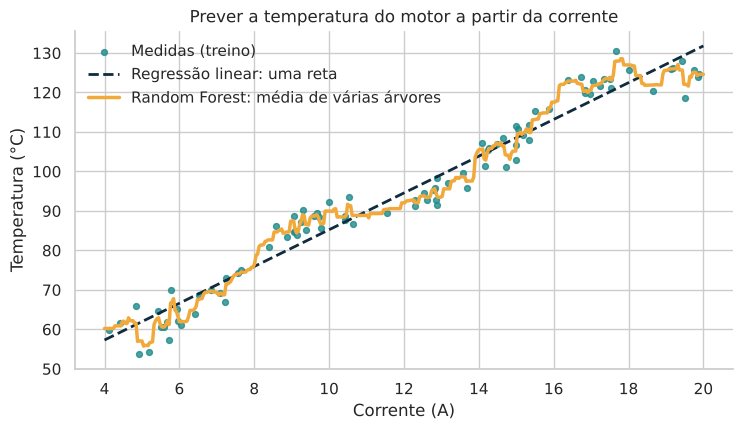

In [6]:

# --- 1) Criar os dados ---
rng = np.random.default_rng(67)
n = 150
corrente = rng.uniform(4, 20, n)                                                       # corrente (A)
temp_motor = 40 + 4.6 * corrente + 4 * np.sin(corrente / 1.2) + rng.normal(0, 3, n)    # temperatura = tendência + curva + ruído (°C)
Xr = corrente[:, None]                                                                 # X precisa ser uma tabela (1 coluna)

# --- 2) Separar treino e teste ---
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, temp_motor, test_size=0.4, random_state=67)

# --- 3) Treinar os dois modelos ---
lin_r = LinearRegression().fit(Xr_tr, yr_tr)                                  # uma reta
rf_r = RandomForestRegressor(n_estimators=100, random_state=67).fit(Xr_tr, yr_tr)   # 100 árvores
print("Reta ajustada: temperatura = α + β × corrente  →  α = %.2f °C | β = %.2f °C por ampère" % (lin_r.intercept_, lin_r.coef_[0]))
print("(β: cada 1 A a mais de corrente aumenta a temperatura em %.2f °C, em média)\n" % lin_r.coef_[0])

linhas_r = []
for nome_m, mod_m in [("Regressão linear", lin_r), ("Random Forest", rf_r)]:
    pr = mod_m.predict(Xr_te)                                                  # previsões no teste
    linhas_r.append({"Modelo": nome_m,
                     "MAE (°C)": mean_absolute_error(yr_te, pr),               # erro médio absoluto
                     "RMSE (°C)": np.sqrt(np.mean((yr_te - pr) ** 2)),         # raiz do erro quadrático médio (pune erros grandes)
                     "R²": r2_score(yr_te, pr)})                               # fração da variação explicada (1 = perfeito)
display(pd.DataFrame(linhas_r).set_index("Modelo").round(3))

# --- 4) Desenhar ---
g = np.linspace(4, 20, 400)[:, None]                                          # pontos para traçar as curvas dos modelos
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.scatter(Xr_tr, yr_tr, color=TEAL, s=18, alpha=0.8, label="Medidas (treino)")
ax.plot(g, lin_r.predict(g), "--", color=NAVY, lw=2, label="Regressão linear: uma reta")
ax.plot(g, rf_r.predict(g), color=ORANGE, lw=2.5, label="Random Forest: média de várias árvores")
ax.set_xlabel("Corrente (A)"); ax.set_ylabel("Temperatura (°C)"); ax.legend(frameon=False); limpa(ax)
ax.set_title("Prever a temperatura do motor a partir da corrente"); plt.show()


**Leitura do gráfico**

- **Eixos:** corrente elétrica do motor (A) na horizontal e temperatura (°C) na vertical. O **alvo** que queremos prever é a **temperatura**; a **entrada** é a **corrente**.
- **Pontos verde-azulados:** as 150 medidas usadas no treino. A nuvem sobe com a corrente, com uma leve curvatura e ruído.
- **Reta tracejada (regressão linear):** a melhor reta. Pela equação, **α = 38,68 °C** (temperatura extrapolada para corrente zero) e **β = 4,66 °C por ampère**. Ela acompanha a tendência geral, mas passa **abaixo** dos pontos entre 8 e 10 A e **acima** deles perto de 20 A, porque a relação não é perfeitamente reta.
- **Linha laranja (Random Forest):** média de várias árvores; acompanha as curvas e os "degraus" dos dados. Nos extremos (4 e 20 A) ela fica **plana**, pois não extrapola além do que viu.
- **Números do teste:** erro médio (MAE) de **2,96 °C** para a reta e **2,34 °C** para a floresta; R² de **0,977** contra **0,982**. Os dois são bons; a reta é mais simples de explicar, e a floresta erra um pouco menos.
- **Na engenharia:** estima a temperatura de operação sem precisar de um sensor térmico em cada motor.


**Perguntas**
1. O que significam o **α** e o **β** da reta? Para que serve o R²?
2. A floresta teve MAE menor (2,3 contra 3,0 °C), mas o R² da reta também é alto (0,98). A reta é ruim?

<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** **α** (intercepto) é a temperatura prevista quando a corrente é zero (≈ 38,7 °C; serve para posicionar a reta, não precisa ser fisicamente realista). **β** é a **inclinação**: cada 1 A a mais de corrente aumenta a temperatura em ≈ 4,66 °C. O **R²** diz que fração da variação da temperatura o modelo explica: 0 = o mesmo que prever sempre a média; 1 = perfeito.

**2.** Não. O R² alto mostra que a tendência geral é quase linear, e a reta é **simples e fácil de explicar** (um α e um β). A floresta ganha por seguir as pequenas curvas (MAE e RMSE menores), mas não dá um β para interpretar. Escolher entre elas é equilibrar **erro** e **interpretabilidade**.

</details>



### Exemplo 4 · SVM: fronteira de maior margem
| | |
|---|---|
| **Problema** | Separar **motores normais de motores com falha** (vibração e temperatura) e **peças boas de peças defeituosas** (temperatura do molde e pressão), usando a fronteira que deixa a **maior folga** entre as classes. |
| **Dados** | Esquerda: 70 motores simulados (35 normais e 35 com falha), com vibração (mm/s) e temperatura (°C). Direita: 160 peças simuladas, com temperatura do molde e pressão padronizadas: as boas ficam no centro e as defeituosas em volta (defeito quando qualquer variável sai da faixa, para cima ou para baixo). |
| **Modelo / técnica** | **SVM** com kernel **linear** (reta) e com kernel **RBF** (fronteira curva). |
| **Como medimos** | Acurácia, precisão e sensibilidade no teste; quantos pontos são vetores de suporte; e quanto a reta e o kernel RBF acertam nas peças. |
| **O que observar** | Só os pontos mais próximos da fronteira (vetores de suporte) a definem. O kernel RBF cria uma fronteira curva. |
| **Nos slides** | 41 |
| **Na apostila** | seção 4.2 e figura 4 |


Fronteira: 0.06·vibração + 0.17·temperatura + -12.30 = 0
Vetores de suporte: 2 de 49 pontos de treino (só eles definem a fronteira)
Teste (21 motores): acurácia = 1.00 | precisão = 1.00 | sensibilidade = 1.00
O que classificou: VN = 11 normais certos | VP = 10 falhas certas | FP = 0 | FN = 0

Peças boas x defeituosas (teste): acurácia com reta = 0.56 | acurácia com kernel RBF = 1.00


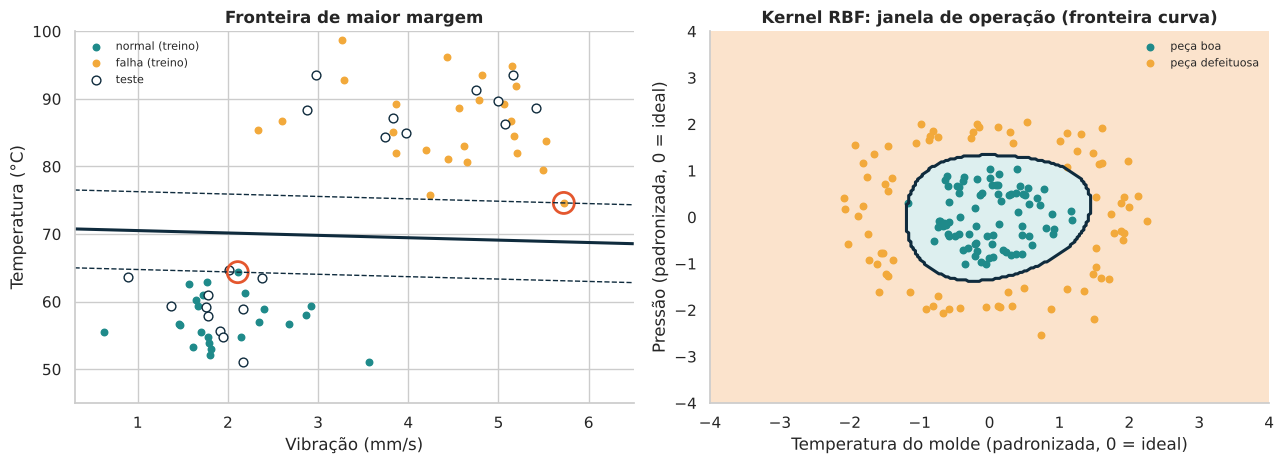

In [7]:

from sklearn.datasets import make_circles                       # gerador de dados em forma de círculos

# --- 1) Dados do painel esquerdo: duas classes separáveis por uma reta ---
rng = np.random.default_rng(3)
va = np.r_[rng.normal(1.9, 0.5, 35), rng.normal(4.6, 0.8, 35)]  # vibração
ta = np.r_[rng.normal(58, 4, 35), rng.normal(86, 5, 35)]        # temperatura
ya_s = np.r_[np.zeros(35), np.ones(35)]                         # 0 = normal, 1 = falha
Xs = np.c_[va, ta]
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ya_s, test_size=0.3, stratify=ya_s, random_state=SEED)   # 70% treino, 30% teste
svm_lin = SVC(kernel="linear", C=1).fit(Xs_tr, ys_tr)           # SVM com fronteira reta (treinado só com o treino)

# --- 2) O que o SVM aprendeu e como foi no teste ---
pred_s = svm_lin.predict(Xs_te)                                 # classe prevista para os motores de teste
w, b = svm_lin.coef_[0], svm_lin.intercept_[0]                  # a reta: w1·vibração + w2·temperatura + b = 0
print("Fronteira: %.2f·vibração + %.2f·temperatura + %.2f = 0" % (w[0], w[1], b))
print("Vetores de suporte: %d de %d pontos de treino (só eles definem a fronteira)" % (len(svm_lin.support_), len(Xs_tr)))
vn_, fp_, fn_, vp_ = confusion_matrix(ys_te, pred_s, labels=[0, 1]).ravel()
print("Teste (%d motores): acurácia = %.2f | precisão = %.2f | sensibilidade = %.2f" % (
      len(ys_te), accuracy_score(ys_te, pred_s), precision_score(ys_te, pred_s), recall_score(ys_te, pred_s)))
print("O que classificou: VN = %d normais certos | VP = %d falhas certas | FP = %d | FN = %d" % (vn_, vp_, fp_, fn_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
ax.scatter(Xs_tr[ys_tr == 0, 0], Xs_tr[ys_tr == 0, 1], color=TEAL, s=22, label="normal (treino)")      # pontos de treino
ax.scatter(Xs_tr[ys_tr == 1, 0], Xs_tr[ys_tr == 1, 1], color=ORANGE, s=22, label="falha (treino)")
ax.scatter(Xs_te[:, 0], Xs_te[:, 1], facecolors="white", edgecolors=NAVY, s=40, label="teste")           # pontos de teste (círculo branco)
xx, yy = np.meshgrid(np.linspace(0.3, 6.5, 200), np.linspace(45, 100, 200))
dec = svm_lin.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)    # distância de cada ponto à fronteira
ax.contour(xx, yy, dec, levels=[-1, 0, 1], colors=NAVY, linestyles=["--", "-", "--"], linewidths=[1, 2.2, 1])   # fronteira e margens
ax.scatter(*svm_lin.support_vectors_.T, s=230, facecolors="none", edgecolors=RED, linewidths=2)   # circula os vetores de suporte
ax.set_xlabel("Vibração (mm/s)"); ax.set_ylabel("Temperatura (°C)"); ax.set_title("Fronteira de maior margem", fontweight="bold"); ax.legend(frameon=False, fontsize=8); limpa(ax)

# --- 3) Dados do painel direito: uma classe cercada pela outra (reta não resolve) ---
Xcir, ycir = make_circles(n_samples=160, factor=0.35, noise=0.12, random_state=3)
Xcir = Xcir * 2.0
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xcir, ycir, test_size=0.3, stratify=ycir, random_state=SEED)
svm_lin2 = SVC(kernel="linear", C=1).fit(Xc_tr, yc_tr)               # SVM com reta (vai falhar)
svm_rbf = SVC(kernel="rbf", gamma="scale", C=5).fit(Xc_tr, yc_tr)    # SVM com kernel RBF: fronteira curva
print("\nPeças boas x defeituosas (teste): acurácia com reta = %.2f | acurácia com kernel RBF = %.2f" % (
      accuracy_score(yc_te, svm_lin2.predict(Xc_te)), accuracy_score(yc_te, svm_rbf.predict(Xc_te))))
ax = axes[1]
xx, yy = np.meshgrid(np.linspace(-4, 4, 250), np.linspace(-4, 4, 250))
zz = svm_rbf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)               # classe prevista em cada ponto
ax.contourf(xx, yy, zz, levels=[-.5, .5, 1.5], colors=["#FBE3CC", "#DDEFEF"])       # pinta as duas regiões
ax.contour(xx, yy, zz, levels=[0.5], colors=NAVY, linewidths=2.2)                    # fronteira
ax.scatter(Xcir[ycir == 1, 0], Xcir[ycir == 1, 1], color=TEAL, s=22, label="peça boa")          # miolo: peças boas
ax.scatter(Xcir[ycir == 0, 0], Xcir[ycir == 0, 1], color=ORANGE, s=22, label="peça defeituosa")  # anel: defeitos nos dois extremos
ax.set_xlabel("Temperatura do molde (padronizada, 0 = ideal)"); ax.set_ylabel("Pressão (padronizada, 0 = ideal)")
ax.set_title("Kernel RBF: janela de operação (fronteira curva)", fontweight="bold"); ax.legend(frameon=False, fontsize=8, loc="upper right"); limpa(ax)
plt.tight_layout(); plt.show()


**Leitura dos gráficos**

- **O problema prático:** o SVM **separa duas classes** com a fronteira mais folgada possível. Aqui, as classes são **motor normal** e **motor com falha**, e as entradas são leituras de sensor.
- **Painel da esquerda (reta):** horizontal = vibração (mm/s), vertical = temperatura (°C). Pontos **verdes** = normais (treino), **laranja** = falha (treino), **círculos brancos** = motores de teste (que o modelo não viu). A **linha cheia** é a fronteira e as **tracejadas** são as margens (a "folga"). Os pontos **circulados em vermelho** são os **vetores de suporte**: são os únicos **2 de 49** pontos de treino que definem a fronteira. A reta ficou quase horizontal porque a **temperatura sozinha já separa** bem as duas classes (normais por volta de 58 °C, falhas por volta de 86 °C).
- **O que o modelo classificou (teste, 21 motores):** acertou **11 normais** e **10 falhas**, nenhum erro: acurácia 1,00. Atenção: com dados simulados e bem separados isso é fácil. Com dados reais haveria erros.
- **Painel da direita (curva):** exemplo de **peças de uma linha de produção**. Horizontal = temperatura do molde e vertical = pressão, ambas **padronizadas** (0 = valor ideal, ±2 = muito longe do ideal). Pontos **verdes** = peças boas, no centro; **laranja** = peças defeituosas, que aparecem quando temperatura **ou** pressão saem da faixa, para qualquer lado. Nenhuma reta separa o miolo do anel: a reta acerta só **56%**. O kernel **RBF** desenha uma fronteira **curva** (a linha escura em volta do grupo verde) e acerta **100%** no teste.
- **Regra prática:** use o kernel linear quando uma reta basta (rápido, fácil de explicar) e o RBF quando o problema tem **janela de operação** (bom no meio, ruim nos dois extremos).


**Perguntas**
1. Por que a acurácia do SVM com reta ficou em 0,56 nos círculos e 1,00 com o kernel RBF?
2. Só 2 de 49 pontos são vetores de suporte. O que isso quer dizer? Qual foi a acurácia nos motores?

<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** Com uma classe **cercada** pela outra, nenhuma **reta** separa os grupos: o SVM linear acerta pouco mais que um palpite (0,56). O **kernel RBF** permite uma fronteira **curva** em volta do grupo central e acerta tudo no teste (1,00).

**2.** Só os **pontos mais próximos da fronteira** (os vetores de suporte, circulados em vermelho) a definem: se os outros 47 mudassem de posição sem cruzar a margem, a fronteira seria a mesma. No teste (21 motores), o SVM com reta classificou **todos** corretamente: 11 normais e 10 falhas (VN = 11, VP = 10, FP = 0, FN = 0), ou seja, acurácia 1,00. As duas classes estão bem separadas; em dados reais, o resultado costuma ser menor.

</details>



### Exemplo 5 · Overfitting: decorar não é aprender
| | |
|---|---|
| **Problema** | Prever a **temperatura do motor** a partir da **corrente** (como no Exemplo 3), mas com **poucas medidas**, e mostrar que um modelo **complexo demais** erra pouco no treino e muito em dados novos. |
| **Dados** | 36 medidas simuladas de corrente (A) e temperatura (°C): 14 para treino e 22 para teste. |
| **Modelo / técnica** | **Regressão polinomial** de grau 1 (simples demais), 3 (equilíbrio) e 13 (complexo demais). |
| **Como medimos** | MAE no treino e no teste, em °C. |
| **O que observar** | Grau 1 (*underfitting*): erra nos dois. Grau 3: erra pouco nos dois. Grau 13 (*overfitting*): erro de treino quase zero e erro de teste enorme. |
| **Nos slides** | 44 |
| **Na apostila** | seção 4.3 e figura 8 |


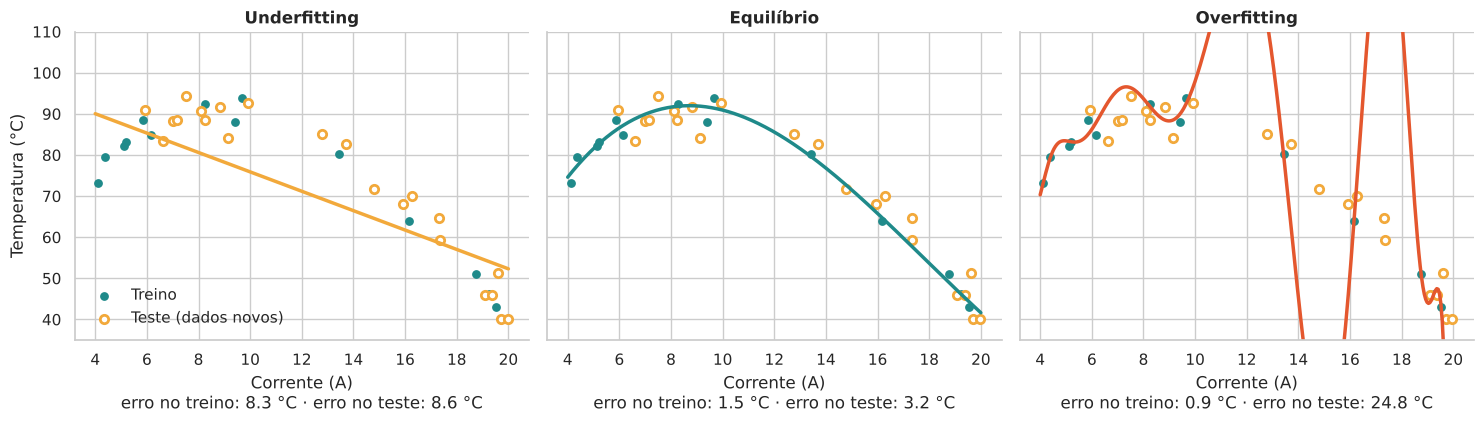

,MAE treino,MAE teste,RMSE teste,R² treino,R² teste
Grau,,,,,
1,8.31,8.56,9.71,0.65,0.72
3,1.54,3.18,3.88,0.99,0.96
13,0.85,24.77,44.97,0.99,-4.99


In [8]:

# --- 1) Criar os dados: temperatura sobe e depois desce com a corrente (forma de morro) ---
rng = np.random.default_rng(199)
n = 36
cor = rng.uniform(4, 20, n)                                                       # corrente (A)
tem = np.clip(88 - 0.405 * (cor - 9) ** 2 + rng.normal(0, 3.5, n), 40, None)      # temperatura (°C) = morro + ruído
c_tr, c_te, t_tr, t_te = train_test_split(cor, tem, test_size=0.6, random_state=199)   # treino e teste

# --- 2) Ajustar polinômios de graus 1, 3 e 13 e desenhar ---
g = np.linspace(4, 20, 300)
tabela_ov = []                                    # vai guardar as métricas de cada grau
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, (grau, titulo, cor_l) in zip(axes, [(1, "Underfitting", ORANGE), (3, "Equilíbrio", TEAL), (13, "Overfitting", RED)]):
    m = make_pipeline(StandardScaler(), PolynomialFeatures(grau), LinearRegression()).fit(c_tr[:, None], t_tr)   # polinômio do grau escolhido
    e_tr = mean_absolute_error(t_tr, m.predict(c_tr[:, None]))      # erro no treino
    e_te = mean_absolute_error(t_te, m.predict(c_te[:, None]))      # erro no teste (dados novos)
    tabela_ov.append({"Grau": grau, "MAE treino": e_tr, "MAE teste": e_te,
                      "RMSE teste": np.sqrt(np.mean((t_te - m.predict(c_te[:, None])) ** 2)),
                      "R² treino": r2_score(t_tr, m.predict(c_tr[:, None])), "R² teste": r2_score(t_te, m.predict(c_te[:, None]))})
    ax.scatter(c_tr, t_tr, color=TEAL, s=28, label="Treino")
    ax.scatter(c_te, t_te, facecolors="white", edgecolors=ORANGE, linewidths=2, s=36, label="Teste (dados novos)")
    ax.plot(g, m.predict(g[:, None]), color=cor_l, lw=2.5); ax.set_ylim(35, 110)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Corrente (A)\nerro no treino: %.1f °C · erro no teste: %.1f °C" % (e_tr, e_te)); limpa(ax)
axes[0].set_ylabel("Temperatura (°C)"); axes[0].legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()
display(pd.DataFrame(tabela_ov).set_index("Grau").round(2))     # tabela: o R² de teste do grau 13 fica negativo (pior que prever a média)


**Leitura dos gráficos** (mesmo problema do Exemplo 3: prever a **temperatura do motor** a partir da **corrente**, agora com poucas medidas)

- **Eixos e pontos:** corrente (A) na horizontal, temperatura (°C) na vertical. **Pontos verdes** = 14 medidas de **treino** (o modelo vê). **Círculos laranja vazados** = 22 medidas de **teste** (dados novos, que o modelo não viu). Abaixo de cada painel está o erro médio no treino e no teste.
- **Painel "Underfitting" (grau 1, uma reta):** simples demais. Erra **8,3 °C no treino e 8,6 °C no teste**: erra parecido nos dois, mas erra muito, porque a temperatura **sobe e depois desce** com a corrente e uma reta não faz curva (R² de teste 0,72).
- **Painel "Equilíbrio" (grau 3):** a curva acompanha o formato real. Erra **1,5 °C no treino e 3,2 °C no teste** (R² de teste 0,96). Um pouco pior no teste é o esperado e saudável.
- **Painel "Overfitting" (grau 13):** a curva passa por quase todos os pontos de treino (erro **0,9 °C**), mas entre eles **oscila loucamente**, chegando a prever temperaturas absurdas, como valores muito acima de 110 °C ou abaixo de 40 °C, para correntes que não mediu. No teste o erro vai a **24,8 °C** e o R² fica **negativo (−4,99)**, pior que simplesmente chutar a média.
- **O que o overfitting representa:** o modelo **decorou o ruído** das 14 medidas em vez de aprender a relação física corrente → temperatura. Na prática, ele parece perfeito na bancada e **falha no motor novo**, e é por isso que sempre se avalia com dados de teste separados.


**Como evitar overfitting:** separar **treino e teste**, usar **validação cruzada**, escolher modelos mais simples e ter mais dados. Veremos isso na prática nas cinco engenharias.

**Perguntas**
1. Qual grau você escolheria? Por quê?
2. O que significa o R² de teste **negativo** (−4,99) no grau 13?
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** O **grau 3**: erro de treino e de teste parecidos e baixos (MAE 1,5 e 3,2 °C; R² de teste 0,96). O grau 1 erra muito nos dois (*underfitting*); o grau 13 erra quase nada no treino (0,85 °C) mas 24,8 °C no teste (*overfitting*).

**2.** R² negativo quer dizer que o modelo é **pior do que simplesmente prever a média** dos dados de teste. O grau 13 "decorou" o treino e inventa curvas absurdas fora dele. **Sempre avalie no teste**, nunca só no treino.

</details>



---
## Bloco 1 · Engenharia Civil: prever a resistência do concreto
**Onde implementar:** na usina de concreto e na obra. O ensaio de resistência aos 28 dias demora quase um mês. Um modelo que estima a resistência a partir do traço e da idade ajuda a **ajustar o traço antes** e a decidir **quando desformar**.

*Resumo do bloco:* dados (1.1) → olhar os dados (1.2) → regressão (1.3) → engenharia de atributos (1.4). Apostila: **capítulo 5**.



### Exercício 1.1 · Criar os dados (simulados)
| | |
|---|---|
| **Problema** | Prever a **resistência do concreto (MPa)** a partir do traço e da idade, sem esperar o ensaio. |
| **Dados** | 600 amostras simuladas com a **Lei de Abrams**: quanto maior a relação água/cimento, menor a resistência; a resistência cresce (e satura) com a idade. Colunas: cimento, água, aditivo, idade e resistência. |
| **Modelo / técnica** | Ainda não há modelo: só construímos a tabela. |
| **Como medimos** | — |
| **O que observar** | O formato da tabela: cada linha é uma amostra de concreto; cada coluna, uma variável. |
| **Nos slides** | 51 e 52 |
| **Na apostila** | cap. 5, seção "Os dados (simulados)" |


In [9]:

rng = np.random.default_rng(SEED)                   # gerador aleatório (mesma semente = mesmos dados para todos)
n = 600                                             # número de amostras de concreto
cimento = rng.uniform(250, 480, n)                  # consumo de cimento, kg/m3 (sorteado entre 250 e 480)
agua = rng.uniform(150, 215, n)                     # água, L/m3
aditivo = rng.uniform(0, 2.0, n)                    # aditivo, % sobre o peso do cimento
idade = rng.choice([3, 7, 14, 28, 56, 90], n)       # idade do ensaio, em dias (um dos seis valores)

ac = agua / cimento                                 # relação água/cimento (a variável mais importante)
f28 = 115 * np.exp(-2.0 * ac) * (1 + 0.06 * aditivo)               # Lei de Abrams: resistência aos 28 dias (MPa)
fator_idade = (idade / (4 + 0.85 * idade)) / (28 / (4 + 0.85 * 28))   # como a resistência evolui com a idade
resistencia = f28 * fator_idade + rng.normal(0, 2.0, n)           # resistência final + erro de ensaio de 2 MPa

civil = pd.DataFrame({"cimento": cimento, "agua": agua, "aditivo": aditivo,
                      "idade": idade, "resistencia_MPa": resistencia})   # monta a tabela
civil["rel_agua_cimento"] = civil["agua"] / civil["cimento"]            # guarda também a relação água/cimento
print(civil.shape)                                  # (linhas, colunas)
display(civil.head())                               # as 5 primeiras linhas
display(civil.describe().T.round(2))                # resumo estatístico: média, desvio, mínimo e máximo


(600, 6)


,cimento,agua,aditivo,idade,resistencia_MPa,rel_agua_cimento
0,428.009891,181.037882,1.132841,14,46.809727,0.422976
1,350.942041,199.493117,1.101818,28,40.498557,0.568450
2,447.477522,208.716312,1.657094,3,21.634441,0.466429
3,410.394647,196.845237,1.421066,28,44.200247,0.479649
4,271.660790,212.608730,0.053156,90,25.563679,0.782626


,count,mean,std,min,25%,50%,75%,max
cimento,600.0,364.08,66.06,251.25,304.45,364.95,422.57,479.79
agua,600.0,182.77,19.18,150.03,165.93,182.07,199.71,214.96
aditivo,600.0,1.01,0.58,0.00,0.49,0.99,1.55,2.00
idade,600.0,32.02,30.60,3.00,7.00,14.00,56.00,90.00
resistencia_MPa,600.0,38.37,13.62,8.09,27.31,38.28,48.83,69.89
rel_agua_cimento,600.0,0.52,0.11,0.33,0.43,0.50,0.60,0.85



### Exercício 1.2 · Visualizar antes de modelar
| | |
|---|---|
| **Problema** | Antes de modelar, entender o que vamos **prever** (a **resistência do concreto, em MPa**) e as variáveis de **entrada** (cimento, água, aditivo e idade): como se distribuem e como se relacionam. |
| **Dados** | A tabela `civil` do passo anterior. |
| **Modelo / técnica** | Gráficos: histograma, dispersão e mapa de calor. |
| **Como medimos** | — |
| **O que observar** | Mais água por cimento, menos resistência. Idade e resistência não formam uma reta (a resistência satura). |
| **Nos slides** | 47, 48 e 52 |
| **Na apostila** | seção 4.6 (visualização) e figura 13 |


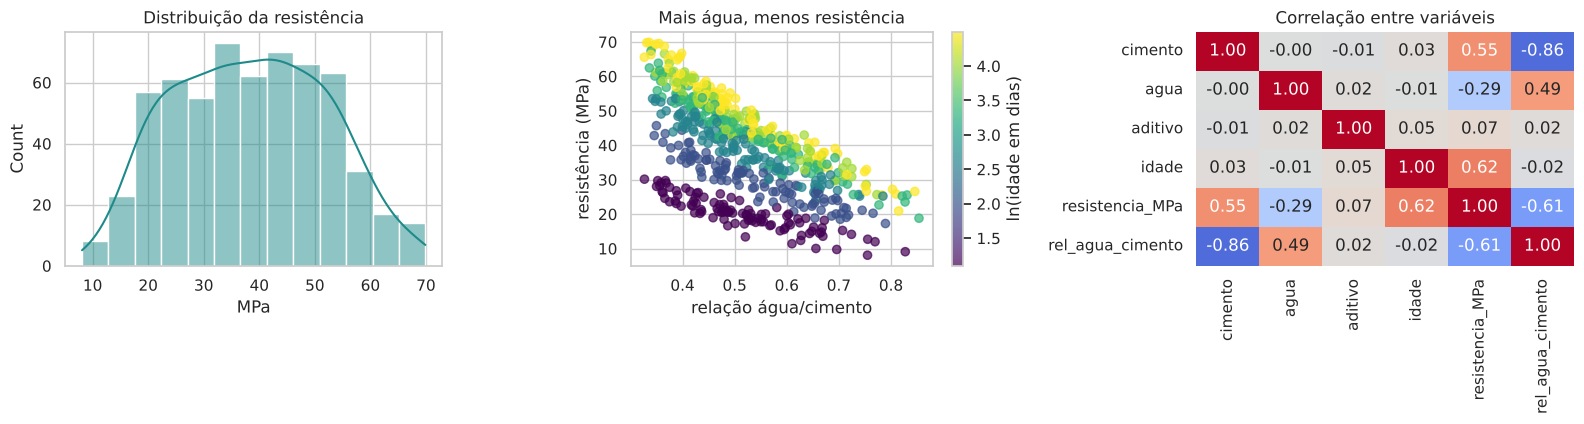

In [10]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))             # 3 gráficos lado a lado

sns.histplot(civil["resistencia_MPa"], kde=True, color=TEAL, ax=axes[0])    # histograma: como a resistência se distribui
axes[0].set_title("Distribuição da resistência"); axes[0].set_xlabel("MPa")

sc = axes[1].scatter(civil["rel_agua_cimento"], civil["resistencia_MPa"],
                     c=np.log(civil["idade"]), cmap="viridis", alpha=0.7)   # dispersão: cada ponto é uma amostra; a cor é a idade
axes[1].set_xlabel("relação água/cimento"); axes[1].set_ylabel("resistência (MPa)")
axes[1].set_title("Mais água, menos resistência")
cb = plt.colorbar(sc, ax=axes[1]); cb.set_label("ln(idade em dias)")

sns.heatmap(civil.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[2], cbar=False)   # mapa de calor: correlações
axes[2].set_title("Correlação entre variáveis")
plt.tight_layout(); plt.show()


**Leitura dos gráficos** (600 amostras de concreto simuladas; o **alvo** que queremos prever depois é a **resistência (MPa)**; as entradas são cimento, água, aditivo e idade)

- **Gráfico A, "Distribuição da resistência" (histograma):** horizontal = resistência (MPa), vertical = quantas amostras caem em cada faixa. As resistências vão de cerca de **8 a 70 MPa**, com a maior parte entre **20 e 60 MPa** e média perto de 40 MPa. Não há um valor dominante nem valores absurdos, então os dados parecem razoáveis para modelar.
- **Gráfico B, "Mais água, menos resistência" (dispersão):** horizontal = relação água/cimento, vertical = resistência (MPa), **cor** = logaritmo da idade (roxo = concreto novo, amarelo = concreto velho). A nuvem **desce** para a direita: quanto mais água por cimento, menor a resistência (Lei de Abrams). Para a mesma relação a/c, os pontos **amarelos ficam acima** dos roxos: concreto mais velho é mais resistente. A idade explica a "faixa" de cores.
- **Gráfico C, "Correlação entre variáveis" (mapa de calor):** cada quadrado é a correlação entre duas variáveis (de −1 a +1; vermelho = positiva forte, azul = negativa forte). A **resistência** correlaciona com **idade (0,62)**, **cimento (0,55)**, **relação a/c (−0,61)** e **água (−0,29)**; o aditivo quase não aparece (0,07). Cimento e relação a/c têm **−0,86** entre si: carregam informação parecida.
- **Atenção:** correlação mede se duas variáveis andam juntas em **linha reta**. A idade tem relação curva com a resistência (satura com o tempo), por isso o 0,62 subestima o quanto ela importa.


**Perguntas**
1. Qual variável mais se relaciona com a resistência? A relação com a água/cimento é uma reta?
2. Por que a idade e a resistência não formam uma reta? (a resistência satura com o tempo)
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** Pela correlação do mapa de calor, as duas variáveis mais ligadas à resistência são a **idade** (+0,62) e a **relação água/cimento** (−0,61); o cimento tem +0,55. A relação com a água/cimento **não é uma reta**: segue a Lei de Abrams, uma curva **exponencial** (cai rápido e depois mais devagar), por isso uma correlação "linear" de −0,61 subestima a força da relação.

**2.** O cimento continua reagindo com a água, mas **cada vez mais devagar**: a resistência sobe muito nos primeiros dias e depois **satura** (hidratação). Por isso o **logaritmo da idade** correlaciona mais (+0,75) do que a idade crua (+0,62), e usamos `log_idade` na seção 1.4.

</details>



### Exercício 1.3 · Regressão: linear x Random Forest
| | |
|---|---|
| **Problema** | Prever a resistência (um **número**) a partir de cimento, água, aditivo e idade. |
| **Dados** | As 600 amostras: 75% para treino e 25% para teste. |
| **Modelo / técnica** | **Regressão linear** (uma soma ponderada das variáveis) x **Random Forest** (300 árvores). |
| **Como medimos** | **MAE** (erro médio em MPa) e **R²** (fração da variação explicada; 1 é perfeito). |
| **O que observar** | O Random Forest erra bem menos (MAE ≈ 2,16 MPa, R² ≈ 0,96) que a reta (MAE ≈ 5,53 MPa). No gráfico, quanto mais perto da linha tracejada, melhor. |
| **Nos slides** | 52 |
| **Na apostila** | cap. 5, seção "Regressão: linear x Random Forest" e figura 13 |


,MAE (MPa),RMSE (MPa),R²
Modelo,,,
Regressão linear,5.526,6.567,0.767
Random Forest,2.160,2.669,0.962


resistência = α + β1·cimento + β2·água + β3·aditivo + β4·idade
α = 26.90 MPa


,β
cimento,0.1072
agua,-0.2038
aditivo,0.9715
idade,0.2680


Cada β diz quanto a resistência muda (em MPa) quando a variável sobe 1 unidade e as outras ficam fixas.


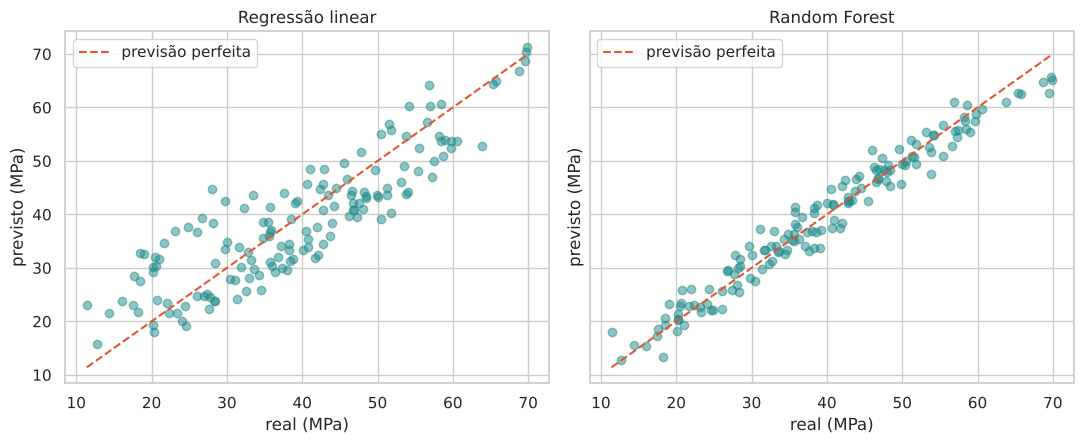

In [11]:

feats_civil = ["cimento", "agua", "aditivo", "idade"]       # variáveis de ENTRADA (X)
X = civil[feats_civil]                                       # tabela de entrada
y = civil["resistencia_MPa"]                                 # o que queremos PREVER (y)

# Regra de ouro: separar treino e teste ANTES de ajustar qualquer modelo
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=SEED)   # 25% fica para teste

modelos_civil = {
    "Regressão linear": LinearRegression(),                                   # modelo 1: uma reta
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEED),   # modelo 2: 300 árvores
}
res = []; prev = {}
for nome, m in modelos_civil.items():                        # repete para cada modelo
    m.fit(X_tr, y_tr)                                        # TREINAR com os dados de treino
    prev[nome] = m.predict(X_te)                             # PREVER a resistência dos dados de teste
    res.append({"Modelo": nome,
                "MAE (MPa)": mean_absolute_error(y_te, prev[nome]),    # erro médio
                "RMSE (MPa)": np.sqrt(np.mean((y_te - prev[nome]) ** 2)),   # raiz do erro quadrático médio
                "R²": r2_score(y_te, prev[nome])})                     # ajuste (1 = perfeito)
tab_civil = pd.DataFrame(res).set_index("Modelo").round(3)
display(tab_civil)

# O que a regressão linear aprendeu: α (intercepto) e um β (peso) para cada variável
lin_civil = modelos_civil["Regressão linear"]
print("resistência = α + β1·cimento + β2·água + β3·aditivo + β4·idade")
print("α = %.2f MPa" % lin_civil.intercept_)
display(pd.DataFrame({"β": lin_civil.coef_}, index=feats_civil).round(4))
print("Cada β diz quanto a resistência muda (em MPa) quando a variável sobe 1 unidade e as outras ficam fixas.")

# Gráfico: previsto x real (ponto na linha tracejada = previsão perfeita)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, (nome, p) in zip(axes, prev.items()):
    ax.scatter(y_te, p, alpha=0.5, color=TEAL)
    lim = [y_te.min(), y_te.max()]
    ax.plot(lim, lim, "--", color=RED, label="previsão perfeita")
    ax.set_title(nome); ax.set_xlabel("real (MPa)"); ax.set_ylabel("previsto (MPa)"); ax.legend()
plt.tight_layout(); plt.show()


**Leitura dos gráficos** (os dois painéis mostram as 150 amostras de **teste**, que os modelos não viram)

- **Como ler um gráfico "real x previsto":** horizontal = resistência **real** medida no ensaio (MPa); vertical = resistência **prevista** pelo modelo (MPa). A **linha tracejada** é a previsão perfeita (previsto = real). Quanto mais perto dela, melhor o modelo.
- **Painel "Regressão linear":** os pontos formam uma nuvem **larga** em volta da linha: erro médio (MAE) de **5,53 MPa**, R² de **0,767**. Para concreto de 30 MPa, o erro típico é de quase 20%.
- **Painel "Random Forest":** os pontos ficam **colados** na linha: MAE de **2,16 MPa** e R² de **0,962**. Ele captura as curvas (efeito da idade e da relação a/c) que a reta não captura.
- **Coeficientes da regressão linear (tabela acima):** o β diz quanto a resistência muda quando a variável sobe 1 unidade e as outras ficam fixas: **cimento +0,107 MPa**, **água −0,204 MPa**, **aditivo +0,97 MPa** e **idade +0,268 MPa** (por unidade de cada variável; a idade em dias). O α (26,90 MPa) é o ponto de partida da conta. Cuidado: o β da idade supõe crescimento **em linha reta** para sempre, o que o concreto não faz.
- **Na engenharia:** prever a resistência a partir do traço e da idade ajuda a decidir, por exemplo, quando desformar, sem esperar o ensaio de laboratório.


**Perguntas**
1. Pelos β da regressão linear, o que mais pesa na resistência? E por que cuidado ao comparar β?
2. O Random Forest tem R² de 0,96 e a reta, 0,77. Isso quer dizer que a reta é inútil?

<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** O **aditivo** tem o maior β (+0,97 MPa por 1 %), a **água** é negativa (−0,20 MPa por litro) e o cimento é positivo (+0,11 MPa por kg/m³). Cuidado: os β dependem da **unidade** de cada variável (litros, kg, % e dias), então não dá para comparar o tamanho deles diretamente. E a relação real é **curva** (Abrams), por isso a reta tem R² de só 0,77.

**2.** Não é inútil: ela entrega α e β **interpretáveis** e já capta a tendência. Mas, com as variáveis cruas, erra em média 5,5 MPa. A seção 1.4 mostra que, com variáveis escolhidas pela física, a mesma reta cai para 3,1 MPa.

</details>



### Exercício 1.4 · Engenharia de atributos: dar ao modelo o que a física ensina
| | |
|---|---|
| **Problema** | Melhorar o modelo **linear** usando o conhecimento de engenharia. |
| **Dados** | As mesmas amostras, agora com novas variáveis: **relação água/cimento** e **logaritmo da idade**. |
| **Modelo / técnica** | **Regressão linear** com as novas variáveis; importância das variáveis no Random Forest. |
| **Como medimos** | MAE e R² no teste (comparar com a seção 1.3). |
| **O que observar** | A reta cai de MAE 5,53 para cerca de 3,10 MPa só com variáveis melhores: **conhecimento do domínio** vale. |
| **Nos slides** | 52 |
| **Na apostila** | cap. 5, seção "Engenharia de atributos" |


Linear com atributos de engenharia: MAE = 3.10 MPa | RMSE = 3.70 MPa | R² = 0.926
α = 48.82 MPa


,β
rel_agua_cimento,-71.112
log_idade,8.627
aditivo,1.466


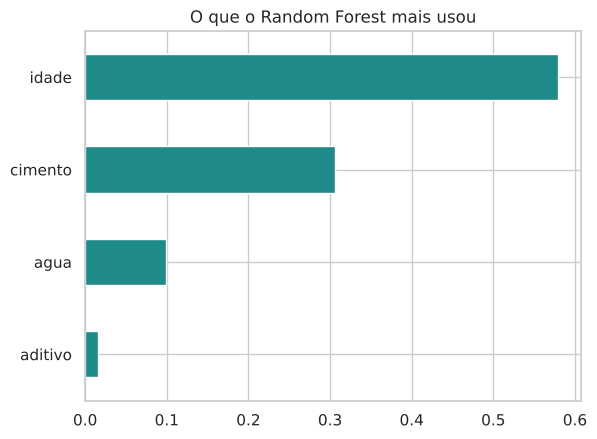

In [12]:

civil["log_idade"] = np.log(civil["idade"])                    # cria a variável: logaritmo da idade
feats2 = ["rel_agua_cimento", "log_idade", "aditivo"]          # novas entradas, escolhidas pela física
X2_tr, X2_te, _, _ = train_test_split(civil[feats2], y, test_size=0.25, random_state=SEED)   # mesma divisão de antes
lin2 = LinearRegression().fit(X2_tr, y_tr)                     # treina de novo a regressão linear
p2 = lin2.predict(X2_te)                                       # previsões no teste
print("Linear com atributos de engenharia: MAE = %.2f MPa | RMSE = %.2f MPa | R² = %.3f" % (
      mean_absolute_error(y_te, p2), np.sqrt(np.mean((y_te - p2) ** 2)), r2_score(y_te, p2)))
print("α = %.2f MPa" % lin2.intercept_)
display(pd.DataFrame({"β": lin2.coef_}, index=feats2).round(3))      # pesos do modelo com variáveis de engenharia

# Quais variáveis o Random Forest mais usou?
imp = pd.Series(modelos_civil["Random Forest"].feature_importances_, index=feats_civil).sort_values()
imp.plot(kind="barh", color=TEAL, title="O que o Random Forest mais usou")
plt.show()


**Leitura do gráfico** (e dos números acima)

- **O que mudou nos números:** a regressão linear com os atributos de engenharia (relação **água/cimento** e **logaritmo da idade**) caiu de MAE **5,53 para 3,10 MPa** e subiu de R² **0,767 para 0,926**, só por receber variáveis que traduzem a física do problema.
- **O gráfico de barras ("O que o Random Forest mais usou"):** cada barra é a **importância** da variável nas decisões da floresta (as barras somam 1). A **idade** é a mais usada (≈ 0,58), depois o **cimento** (≈ 0,31), a **água** (≈ 0,10) e o **aditivo** (≈ 0,015, quase nada). Isso confirma o mapa de calor: idade e cimento mandam; o aditivo, neste conjunto, pouco contribui.
- **Cuidado:** importância mostra o que o modelo **usou**, não prova causa. Variáveis parecidas (cimento e relação a/c) dividem a importância entre si.


**Perguntas**
1. O modelo linear melhorou ao receber a variável `rel_agua_cimento`? O que isso diz sobre **conhecimento do domínio**?
2. O Random Forest descobriu sozinho essa relação? Qual a vantagem e qual o custo (interpretabilidade)?
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** Sim: o MAE caiu de 5,53 para ≈ 3,10 MPa e o R² subiu de 0,77 para 0,93, **sem mudar o algoritmo**, só os dados de entrada. O β de `rel_agua_cimento` é grande e negativo (≈ −71): mais água por cimento, menos resistência. Isso mostra o valor do **conhecimento do domínio**: a física já sabia qual variável importava.

**2.** Sim, quase: o Random Forest chegou a MAE ≈ 2,16 MPa **sem receber** a relação água/cimento pronta, porque faz muitos cortes e acompanha a curva. A **vantagem** é não precisar conhecer a fórmula. O **custo** é a interpretabilidade (não há um β por variável, só a importância) e a extrapolação ruim para valores fora da faixa vista no treino.

</details>



---
## Bloco 2 · Engenharia de Produção: qualidade na linha de produção
**Onde implementar:** em uma linha de injeção, usinagem ou montagem. O modelo recebe os parâmetros do processo e **sinaliza a peça com risco de defeito** antes da inspeção final, reduzindo refugo e retrabalho.

*Resumo do bloco:* dados (2.1) → modelos e a armadilha da acurácia (2.2) → árvore, validação e limiar (2.3) → métricas (2.4) → curva ROC (2.5). Apostila: **capítulo 6** e **seção 4.2**.

Ponto central: **defeitos são raros** (cerca de 10%). Um "modelo" que diz sempre *peça boa* acerta ~90% e não serve para nada.



### Exercício 2.1 · Criar e visualizar os dados
| | |
|---|---|
| **Problema** | Dizer se uma peça sai **boa** ou **defeituosa** a partir dos parâmetros do processo. |
| **Dados** | 2.500 peças simuladas: temperatura do molde, pressão, velocidade, umidade e desgaste da ferramenta. Cerca de 11,6% têm defeito. O defeito aparece quando temperatura ou pressão saem da faixa ideal **em qualquer sentido**. |
| **Modelo / técnica** | Ainda não há modelo. |
| **Como medimos** | — |
| **O que observar** | Poucos defeitos (classes **desbalanceadas**) e defeitos nas **bordas** da faixa ideal, não em uma única direção. |
| **Nos slides** | 53 e 54 |
| **Na apostila** | cap. 6, seção "Os dados (simulados)" e figura 14 |


In [13]:

rng = np.random.default_rng(SEED)
n = 2500                                         # número de peças
temp_molde = rng.normal(210, 8, n)               # temperatura do molde, °C (média 210, desvio 8)
pressao = rng.normal(95, 6, n)                   # pressão, bar
velocidade = rng.normal(1.2, 0.15, n)            # velocidade de injeção, m/s
umidade = rng.normal(45, 8, n)                   # umidade, %
desgaste = rng.uniform(0, 500, n)                # horas de uso da ferramenta

# O defeito cresce quando temperatura ou pressão saem da faixa ideal (em qualquer sentido) e com o desgaste
z = (-9.5 + 0.03 * (temp_molde - 210) ** 2 + 0.04 * (pressao - 95) ** 2 + 0.006 * desgaste
     + 0.5 * (velocidade - 1.2) / 0.15 + 0.03 * (umidade - 45))      # "pontuação de risco" de cada peça
defeito = np.random.default_rng(1).binomial(1, 1 / (1 + np.exp(-z)))  # sorteia defeito (1) ou peça boa (0) conforme o risco

producao = pd.DataFrame({"temp_molde_C": temp_molde, "pressao_bar": pressao, "velocidade_m_s": velocidade,
                         "umidade_pct": umidade, "desgaste_h": desgaste, "defeito": defeito})
print("Peças:", len(producao), "| taxa de defeitos: %.1f%%" % (100 * producao["defeito"].mean()))
display(producao.head())


Peças: 2500 | taxa de defeitos: 11.6%


,temp_molde_C,pressao_bar,velocidade_m_s,umidade_pct,desgaste_h,defeito
0,212.437737,98.318461,1.161307,52.488905,390.724154,0
1,201.680127,96.493482,1.155077,27.622415,124.668426,0
2,216.003610,101.052010,1.095501,40.561659,410.420688,0
3,217.524518,97.906721,1.264272,44.563081,88.566775,0
4,194.391718,102.306351,1.235197,46.843917,179.736761,1


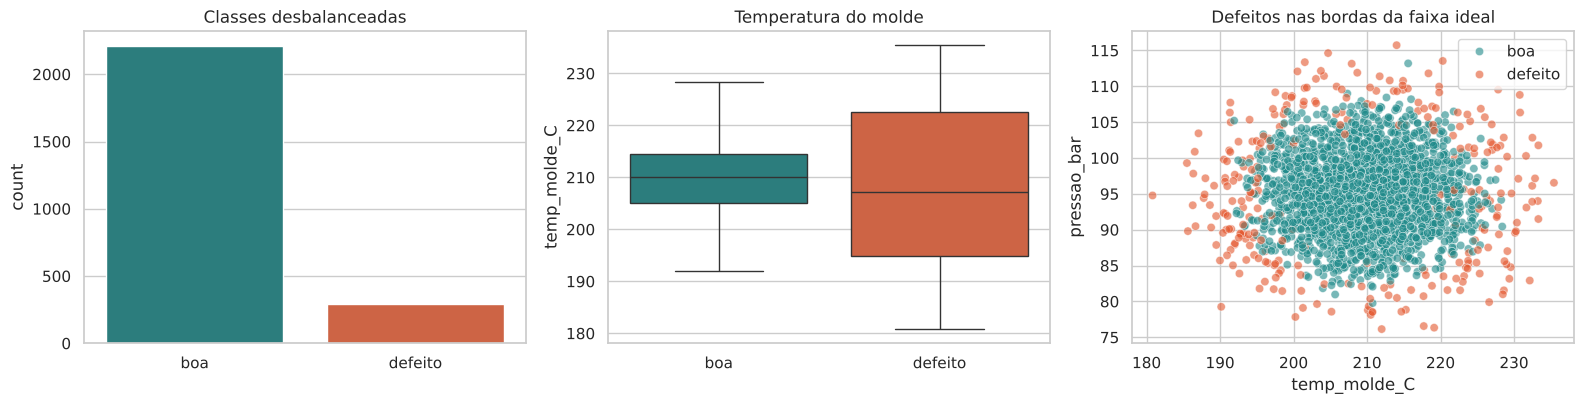

In [14]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
rot = producao["defeito"].map({0: "boa", 1: "defeito"})          # troca 0/1 por texto, para os gráficos
sns.countplot(x=rot, hue=rot, palette=[TEAL, RED], legend=False, ax=axes[0])     # quantas peças de cada classe
axes[0].set_title("Classes desbalanceadas"); axes[0].set_xlabel("")
sns.boxplot(data=producao, x=rot, y="temp_molde_C", hue=rot, palette=[TEAL, RED], legend=False, ax=axes[1])   # boxplot da temperatura
axes[1].set_title("Temperatura do molde"); axes[1].set_xlabel("")
sns.scatterplot(data=producao, x="temp_molde_C", y="pressao_bar", hue=rot,
                palette={"boa": TEAL, "defeito": RED}, alpha=0.6, ax=axes[2])        # dispersão temperatura x pressão
axes[2].set_title("Defeitos nas bordas da faixa ideal"); axes[2].legend(title="")
plt.tight_layout(); plt.show()


**Leitura dos gráficos** (2.500 peças simuladas; queremos prever se a peça sai **boa** ou **defeituosa**)

- **Gráfico A, "Classes desbalanceadas":** horizontal = classe, vertical = quantidade de peças. Há cerca de **2.200 peças boas** contra cerca de **290 defeituosas** (≈ 11,6%). Defeitos são raros, e isso afeta como avaliamos o modelo (próximo exercício).
- **Gráfico B, "Temperatura do molde" (boxplot):** cada caixa mostra onde estão 50% das peças (a linha no meio é a mediana). As peças boas ficam numa caixa **estreita** (cerca de 205 a 215 °C). As defeituosas têm uma caixa **larga**, e a mediana é **parecida** com a das boas. Ou seja, o defeito **não** é "temperatura alta": ele aparece quando a temperatura sai da faixa para **cima ou para baixo**.
- **Gráfico C, "Defeitos nas bordas da faixa ideal" (dispersão):** horizontal = temperatura do molde (°C), vertical = pressão (bar). Pontos verde-azulados = peças boas, concentrados no **centro**; pontos **laranja** = defeitos, nas **bordas** (muito quente, muito frio, pressão muito alta ou muito baixa). Nenhuma reta separa essas classes, então modelos lineares vão ter dificuldade.
- **Na engenharia:** o processo tem uma **janela ideal**; sair dela, para qualquer lado, aumenta o defeito.


### Exercício 2.2 · Classificação e a armadilha da acurácia
| | |
|---|---|
| **Problema** | Treinar três classificadores e ver por que a **acurácia sozinha engana**. |
| **Dados** | As 2.500 peças: 75% treino e 25% teste (625 peças, 72 defeituosas), com `stratify` para manter a proporção de defeitos. |
| **Modelo / técnica** | **Regressão logística**, **árvore de decisão** (profundidade 4) e **Random Forest** (300 árvores), com `class_weight="balanced"` (dá mais peso à classe rara). |
| **Como medimos** | Acurácia, **sensibilidade (recall)**, **precisão** e F1. |
| **O que observar** | A logística acerta 88,5% e acha **zero** defeitos (igual a dizer sempre "boa"). O Random Forest acha 53 dos 72. |
| **Nos slides** | 54 |
| **Na apostila** | cap. 6, seção "Quatro modelos e a armadilha da acurácia" e figura 14 |


In [15]:

feats_prod = ["temp_molde_C", "pressao_bar", "velocidade_m_s", "umidade_pct", "desgaste_h"]   # entradas (X)
Xp = producao[feats_prod]; yp = producao["defeito"]                                         # yp: 0 = boa, 1 = defeito
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, yp, test_size=0.25, stratify=yp, random_state=SEED)   # stratify mantém a proporção

acc_base = 1 - yp_te.mean()                      # acurácia de um "modelo" que SEMPRE diz "peça boa"
print("Acurácia de um 'modelo' que nunca prevê defeito: %.1f%%" % (100 * acc_base))

modelos_prod = {
    "Regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),   # fronteira reta
    "Árvore de decisão": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED),
}
linhas = []
for nome, m in modelos_prod.items():
    m.fit(Xp_tr, yp_tr)                          # treina
    pred = m.predict(Xp_te)                      # prevê "boa" (0) ou "defeito" (1) no teste
    linhas.append({"Modelo": nome,
                   "Acurácia": accuracy_score(yp_te, pred),                          # acertos no total
                   "Recall (defeitos achados)": recall_score(yp_te, pred),           # dos defeitos reais, quantos achou
                   "Precisão (alertas certos)": precision_score(yp_te, pred, zero_division=0),   # dos alertas, quantos eram defeito
                   "Especificidade (boas liberadas)": recall_score(yp_te, pred, pos_label=0),    # das peças boas, quantas liberou
                   "F1": f1_score(yp_te, pred)})
tab_prod = pd.DataFrame(linhas).set_index("Modelo").round(3)
display(tab_prod)


Acurácia de um 'modelo' que nunca prevê defeito: 88.5%


,Acurácia,Recall (defeitos achados),Precisão (alertas certos),Especificidade (boas liberadas),F1
Modelo,,,,,
Regressão logística,0.885,0.000,0.000,1.000,0.000
Árvore de decisão,0.896,0.708,0.537,0.920,0.611
Random Forest,0.939,0.736,0.736,0.966,0.736


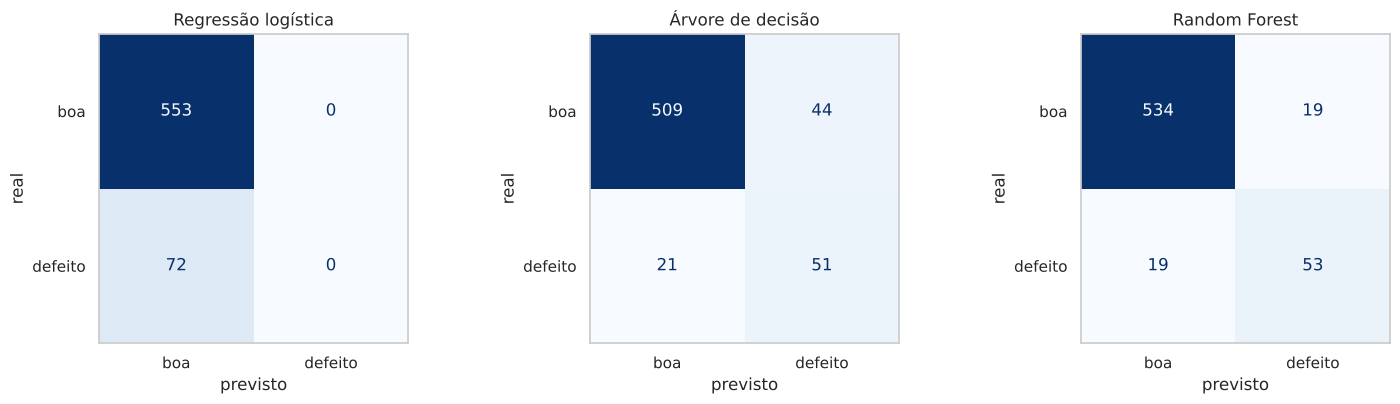

In [16]:

# Matriz de confusão de cada modelo (linhas = real, colunas = previsto)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (nome, m) in zip(axes, modelos_prod.items()):
    matriz(yp_te, m.predict(Xp_te), ax, [0, 1], ["boa", "defeito"], titulo=nome)
plt.tight_layout(); plt.show()


**Leitura dos gráficos** (matrizes de confusão no teste: 625 peças, 72 defeituosas)

- **Como ler uma matriz:** **linhas** = o que a peça realmente é; **colunas** = o que o modelo previu. A diagonal (de cima à esquerda para baixo à direita) são os **acertos**; fora da diagonal, os erros. Números maiores têm fundo azul mais escuro.
- **Regressão logística:** acertou as 553 peças boas, mas **0 dos 72 defeitos**: previu "boa" sempre. A acurácia seria 88,5% (553/625) e o modelo seria **inútil**: essa é a armadilha da acurácia.
- **Árvore de decisão:** achou **51 dos 72** defeitos, mas gerou **44 falsos alarmes** (peças boas marcadas como defeito).
- **Random Forest:** achou **53 dos 72** defeitos e teve **19 falsos alarmes**: é o melhor equilíbrio entre os três.
- **Lição:** com classes raras, olhe a matriz e as métricas por classe, não só a acurácia.


**Perguntas**
1. Por que a **regressão logística** não achou os defeitos? (dica: tanto temperatura *baixa* quanto *alta* causam defeito; uma reta não representa isso)
2. Na linha, o que custa mais: **deixar passar** uma peça defeituosa (falso negativo) ou **refugar** uma peça boa (falso positivo)? Isso muda a métrica e o limiar?
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** O defeito aparece nos **dois extremos**: temperatura muito baixa **ou** muito alta (e o mesmo para a pressão). A regressão logística só sabe fazer uma fronteira **reta** (quanto mais temperatura, mais risco, sempre no mesmo sentido), o que não separa esse padrão em "U". Como só ~11,6% das peças são defeituosas, o melhor palpite dela é "peça boa" para todas: acurácia 88,5%, **sensibilidade 0** (nenhum defeito achado).

**2.** Depende do **custo de cada erro**. Em peça de **segurança** (freio), deixar passar um defeito (**falso negativo**) pode causar acidente: priorize **sensibilidade** e use limiar baixo. Em uma peça barata, refugar uma peça boa (**falso positivo**) pode custar mais do que o defeito: priorize **precisão**. A métrica e o limiar devem refletir isso.

</details>



### Exercício 2.3 · Interpretar a árvore, validar e ajustar o limiar
| | |
|---|---|
| **Problema** | Explicar a decisão a um gestor, conferir se o resultado é estável e escolher quando emitir o alerta. |
| **Dados** | Os mesmos dados e modelos do passo 2.2. |
| **Modelo / técnica** | Árvore lida como regras "se... então..."; **validação cruzada** (5 partes); **limiar de decisão** do Random Forest. |
| **Como medimos** | Recall médio ± desvio na validação cruzada; recall e precisão para cada limiar. |
| **O que observar** | Limiar baixo acha mais defeitos, mas gera mais alarmes falsos; limiar alto faz o contrário. |
| **Nos slides** | 54 |
| **Na apostila** | cap. 6, seção "Validação cruzada e limiar de decisão" |


In [17]:

arvore = modelos_prod["Árvore de decisão"]
print(export_text(arvore, feature_names=feats_prod, max_depth=3))    # a árvore escrita como regras

# Validação cruzada: repete treino/teste em 5 divisões diferentes. O resultado é confiável?
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for nome in ["Árvore de decisão", "Random Forest"]:
    s = cross_val_score(modelos_prod[nome], Xp, yp, cv=cv, scoring="recall")    # recall em cada uma das 5 divisões
    print("%-18s recall médio = %.3f ± %.3f" % (nome, s.mean(), s.std()))      # média ± desvio (desvio grande = instável)

# Limiar de decisão: o modelo dá uma PROBABILIDADE de defeito; o limiar decide quando alertar
prob = modelos_prod["Random Forest"].predict_proba(Xp_te)[:, 1]       # probabilidade de defeito de cada peça
lin = []
for lim in (0.2, 0.3, 0.4, 0.5, 0.6, 0.7):
    pred = (prob >= lim).astype(int)             # alerta se a probabilidade passar do limiar
    lin.append({"limiar": lim, "recall": recall_score(yp_te, pred),
                "precisão": precision_score(yp_te, pred, zero_division=0), "alarmes": int(pred.sum())})
display(pd.DataFrame(lin).round(3))


|--- temp_molde_C <= 198.63
|   |--- temp_molde_C <= 194.63
|   |   |--- velocidade_m_s <= 0.98
|   |   |   |--- class: 0
|   |   |--- velocidade_m_s >  0.98
|   |   |   |--- desgaste_h <= 50.20
|   |   |   |   |--- class: 0
|   |   |   |--- desgaste_h >  50.20
|   |   |   |   |--- class: 1
|   |--- temp_molde_C >  194.63
|   |   |--- pressao_bar <= 87.03
|   |   |   |--- desgaste_h <= 19.61
|   |   |   |   |--- class: 0
|   |   |   |--- desgaste_h >  19.61
|   |   |   |   |--- class: 1
|   |   |--- pressao_bar >  87.03
|   |   |   |--- pressao_bar <= 101.52
|   |   |   |   |--- class: 0
|   |   |   |--- pressao_bar >  101.52
|   |   |   |   |--- class: 1
|--- temp_molde_C >  198.63
|   |--- temp_molde_C <= 221.93
|   |   |--- pressao_bar <= 104.43
|   |   |   |--- pressao_bar <= 83.73
|   |   |   |   |--- class: 1
|   |   |   |--- pressao_bar >  83.73
|   |   |   |   |--- class: 0
|   |   |--- pressao_bar >  104.43
|   |   |   |--- pressao_bar <= 107.35
|   |   |   |   |--- class: 1
|

Random Forest      recall médio = 0.848 ± 0.042


,limiar,recall,precisão,alarmes
0,0.2,0.903,0.560,116
1,0.3,0.875,0.618,102
2,0.4,0.819,0.711,83
3,0.5,0.736,0.726,73
4,0.6,0.597,0.782,55
5,0.7,0.528,0.809,47



**Pergunta:** que limiar você escolheria numa linha de **peças de segurança** (freios)? E numa linha de **embalagens** simples?
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**Freios:** limiar baixo, em torno de **0,2**: sensibilidade ≈ 0,90 (acha 9 em cada 10 defeitos), ao custo de precisão ≈ 0,56 (116 peças sinalizadas para 72 defeituosas). Inspecionar peças a mais é barato perto de um acidente.

**Embalagens:** limiar mais alto, em torno de **0,5 a 0,6**: precisão ≈ 0,73 a 0,78 e bem menos alarmes (73 a 55), ao custo de achar menos defeitos (sensibilidade 0,74 a 0,60). Um defeito eventual custa pouco; muitos alarmes falsos atrapalham a produção.

</details>



### Exercício 2.4 · Métricas: como saber se a classificação funciona?
| | |
|---|---|
| **Problema** | Ler a **matriz de confusão** do Random Forest (peça boa x defeituosa) e calcular as métricas à mão. |
| **Dados** | As 625 peças de teste (72 defeituosas). |
| **Modelo / técnica** | Random Forest (já treinado em 2.2). |
| **Como medimos** | **Acurácia**, **precisão**, **sensibilidade** e **especificidade**. |
| **O que observar** | VN = 534, FP = 19, FN = 19, VP = 53. Sensibilidade: dos defeitos reais, quantos achamos. Especificidade: das peças boas, quantas liberamos. |
| **Nos slides** | 42 e 54 |
| **Na apostila** | seção 4.2 (tabela de métricas) e figura 6 |



| Métrica | Fórmula | Pergunta que responde |
|---|---|---|
| Acurácia | (VP + VN) ÷ total | Quanto acertamos em geral? (engana com classes raras) |
| Precisão | VP ÷ (VP + FP) | Dos alertas, quantos eram defeitos de verdade? |
| Sensibilidade (recall) | VP ÷ (VP + FN) | Dos defeitos reais, quantos foram achados? |
| Especificidade | VN ÷ (VN + FP) | Das peças boas, quantas foram liberadas corretamente? |

**VP** = defeito achado · **VN** = peça boa liberada · **FP** = alarme falso · **FN** = defeito que passou.


VN = 534 | FP = 19 | FN = 19 | VP = 53 | total = 625 peças (72 defeituosas)
Acurácia       = (VP+VN)/total   = 93.9%
Precisão       = VP/(VP+FP)      = 73.6%
Sensibilidade  = VP/(VP+FN)      = 73.6%   (defeitos que o modelo achou)
Especificidade = VN/(VN+FP)      = 96.6%   (peças boas liberadas)


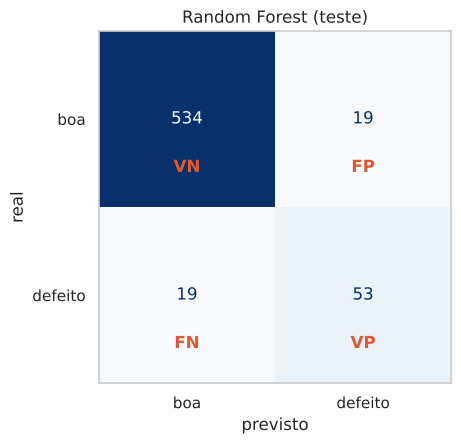

In [18]:

rf_p = modelos_prod["Random Forest"]                       # o modelo que vamos avaliar
pred_rf = rf_p.predict(Xp_te)                              # previsões no teste
vn, fp, fn, vp = confusion_matrix(yp_te, pred_rf, labels=[0, 1]).ravel()     # os 4 números da matriz
print("VN = %d | FP = %d | FN = %d | VP = %d | total = %d peças (%d defeituosas)" % (vn, fp, fn, vp, len(yp_te), yp_te.sum()))
print("Acurácia       = (VP+VN)/total   = %.1f%%" % (100 * (vp + vn) / len(yp_te)))
print("Precisão       = VP/(VP+FP)      = %.1f%%" % (100 * vp / (vp + fp)))
print("Sensibilidade  = VP/(VP+FN)      = %.1f%%   (defeitos que o modelo achou)" % (100 * vp / (vp + fn)))
print("Especificidade = VN/(VN+FP)      = %.1f%%   (peças boas liberadas)" % (100 * vn / (vn + fp)))

fig, ax = plt.subplots(figsize=(5.6, 4.6))
matriz(yp_te, pred_rf, ax, [0, 1], ["boa", "defeito"], titulo="Random Forest (teste)")
for (i, j), nome in zip([(0, 0), (0, 1), (1, 0), (1, 1)], ["VN", "FP", "FN", "VP"]):
    ax.text(j, i + 0.30, nome, ha="center", color=RED, fontweight="bold")      # escreve VN, FP, FN, VP em cada quadrado
plt.tight_layout(); plt.show()


**Leitura do gráfico** (matriz de confusão do Random Forest, 625 peças de teste)

- **Os quatro quadrantes:** **VN = 534** (peça boa, prevista boa: liberada corretamente); **FP = 19** (peça boa, prevista defeito: **falso alarme**, vai para retrabalho sem precisar); **FN = 19** (peça com defeito prevista boa: **defeito que escapou**, o erro mais caro); **VP = 53** (defeito corretamente achado).
- **Como cada métrica sai da matriz:** **acurácia** = (53 + 534)/625 = **93,9%** (acertos no total); **precisão** = 53/(53 + 19) = **73,6%** (dos alertas, quantos eram defeito); **sensibilidade** = 53/(53 + 19) = **73,6%** (dos defeitos reais, quantos achamos); **especificidade** = 534/(534 + 19) = **96,6%** (das peças boas, quantas liberamos).
- **Na engenharia:** a acurácia de 93,9% parece ótima, mas ainda deixamos escapar 19 de 72 defeitos (26%). Quem decide se isso é aceitável é o **custo do erro** (peça defeituosa chegando ao cliente x retrabalho de peça boa).


**Perguntas**
1. Qual a diferença entre **sensibilidade** e **especificidade** neste exemplo?
2. A acurácia é 93,9%, a precisão e a sensibilidade são 73,6%. O modelo está "bom"?

<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** **Sensibilidade (73,6%)**: dos 72 defeitos reais, achamos 53 (VP); 19 passaram (FN). **Especificidade (96,6%)**: das 553 peças boas, liberamos 534 (VN); 19 foram alarmes falsos (FP). A primeira mede o risco de **deixar defeito passar**; a segunda, o de **refugar peça boa**.

**2.** Depende do uso. A acurácia (93,9%) parece alta, mas é puxada pelas 553 peças boas (classe majoritária). Para peça de segurança, 26% de defeitos sem alerta (sensibilidade 73,6%) é muito; por isso usamos a curva ROC e baixamos o limiar. O "bom" só existe **em relação ao custo dos erros**.

</details>



### Exercício 2.5 · Curva ROC: o efeito do limiar de decisão
| | |
|---|---|
| **Problema** | Ver, em um só gráfico, o que acontece com a **sensibilidade** (defeitos achados) e os **falsos alarmes** (peças boas reprovadas) quando mudamos o limiar. |
| **Dados** | As probabilidades do Random Forest nas 625 peças de teste. |
| **Modelo / técnica** | Curva **ROC** e **AUC** (área sob a curva). |
| **Como medimos** | AUC: 0,5 é o acaso; 1,0 é perfeito. |
| **O que observar** | AUC ≈ 0,96. Limiar 0,2: acha ~90% dos defeitos com ~9% de falsos alarmes. Limiar 0,5: ~74% e ~4%. |
| **Nos slides** | 43 e 54 |
| **Na apostila** | seção 4.2 (curva ROC) e figura 7 |


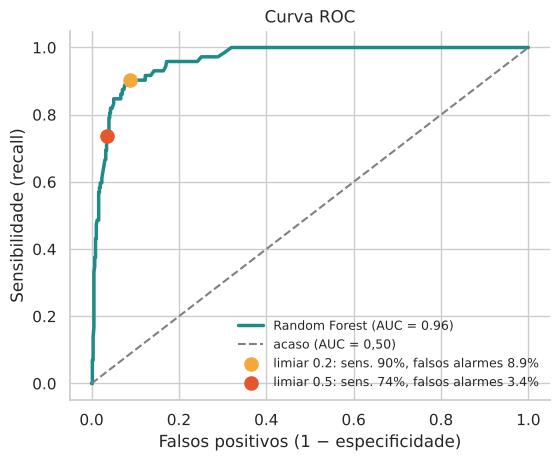

In [19]:

prob_rf = rf_p.predict_proba(Xp_te)[:, 1]                 # probabilidade de defeito de cada peça
fpr, tpr, lims = roc_curve(yp_te, prob_rf)                # taxa de falsos positivos e sensibilidade para cada limiar
auc = roc_auc_score(yp_te, prob_rf)                       # área sob a curva

def ponto(lim):
    """Sensibilidade e taxa de falsos positivos para um limiar escolhido."""
    pred = (prob_rf > lim).astype(int)
    return recall_score(yp_te, pred), 1 - recall_score(yp_te, pred, pos_label=0)

fig, ax = plt.subplots(figsize=(6.2, 4.8))
ax.plot(fpr, tpr, color=TEAL, lw=2.5, label="Random Forest (AUC = %.2f)" % auc)     # a curva ROC
ax.plot([0, 1], [0, 1], "--", color="gray", label="acaso (AUC = 0,50)")              # modelo que chuta
for lim, cor_p in [(0.2, ORANGE), (0.5, RED)]:                                       # destaca dois limiares
    s_, f_ = ponto(lim)
    ax.scatter(f_, s_, s=90, color=cor_p, zorder=5,
               label="limiar %.1f: sens. %.0f%%, falsos alarmes %.1f%%" % (lim, 100 * s_, 100 * f_))
ax.set_xlabel("Falsos positivos (1 − especificidade)"); ax.set_ylabel("Sensibilidade (recall)")
ax.legend(frameon=False, loc="lower right", fontsize=9); limpa(ax); ax.set_title("Curva ROC"); plt.show()


**Leitura do gráfico**

- **Eixos:** horizontal = **falsos positivos** (fração das peças **boas** que o modelo reprova, 1 − especificidade); vertical = **sensibilidade** (fração dos defeitos que ele acha). Cada ponto da curva verde é um **limiar de decisão** diferente (a partir de que probabilidade emitimos o alerta).
- **Linha cinza tracejada:** um modelo que chuta (AUC = 0,50). Quanto mais a curva se afasta dela para o canto superior esquerdo, melhor.
- **Curva verde (Random Forest):** AUC = **0,96** (1,0 seria perfeito). A curva sobe quase vertical e depois se achata.
- **Ponto vermelho (limiar 0,5):** acha **74%** dos defeitos com **3,4%** de falsos alarmes. **Ponto laranja (limiar 0,2):** acha **90%** dos defeitos, mas com **8,9%** de falsos alarmes.
- **Na engenharia:** baixar o limiar acha mais defeitos e reprova mais peças boas. Se um defeito que escapa custa muito mais que um retrabalho, escolha o ponto laranja; se o retrabalho é caro, o vermelho.


**Pergunta:** em peça de segurança, você escolhe o limiar 0,2 ou 0,5? O que se ganha e o que se paga? (mais defeitos achados, mais alarmes falsos)
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

Em **peça de segurança**, escolha o limiar **0,2**: a curva mostra sensibilidade ≈ 90% com ≈ 9% de falsos alarmes (das 553 peças boas, ≈ 51 sinalizadas à toa). **Ganha-se** defeitos achados (de 53 para ≈ 65 dos 72); **paga-se** mais inspeção e refugo desnecessários. Com o limiar **0,5**, a sensibilidade cai para ≈ 74%, com ≈ 3,4% de falsos alarmes. Para peças simples, 0,5 costuma bastar. A **AUC** (0,96) diz que o modelo separa bem as classes **em geral**; o **limiar** é a escolha de negócio.

</details>



---
## Bloco 3 · Engenharia Elétrica: motores, perfis de operação e anomalias
**Onde implementar:** em motores, transformadores e painéis com sensores de corrente, vibração e temperatura. Sem rótulos de falha, o **aprendizado não supervisionado** descobre os regimes de operação e **sinaliza o que foge do padrão** (manutenção preditiva).

*Resumo do bloco:* dados (3.1) → visualizar (3.2) → k-means (3.3) → hierárquico (3.4) → Isolation Forest (3.5) → resumo (3.6). Apostila: **capítulo 7** e **seção 4.4**.

**Diferença importante:** aqui **não há resposta pronta** (rótulo) para o modelo aprender. Ele procura estrutura nos próprios dados.



### Exercício 3.1 · Criar os dados (simulados)
| | |
|---|---|
| **Problema** | Descobrir **quantos regimes de operação** existem nos motores e **quais leituras são anormais**. |
| **Dados** | 1.200 leituras de motores em 3 regimes de carga (baixa, média, alta): rotação, corrente, vibração, temperatura e falha (12,4%). |
| **Modelo / técnica** | Ainda não há modelo. |
| **Como medimos** | — |
| **O que observar** | A coluna `regime` existe, mas **não será mostrada aos algoritmos**: serve só para conferirmos depois. |
| **Nos slides** | 55 e 56 |
| **Na apostila** | cap. 7, seção "Os dados (simulados)" |


In [20]:

rng = np.random.default_rng(SEED)
n = 1200                                                                     # número de leituras
regime = rng.choice(["baixa", "media", "alta"], size=n, p=[0.4, 0.35, 0.25])  # regime de carga de cada leitura (40%, 35%, 25%)
base = {"baixa": (1200, 8.0), "media": (1800, 12.0), "alta": (2400, 17.0)}    # (rotação rpm, corrente A) típicas de cada regime
rpm = np.array([base[r][0] for r in regime]) + rng.normal(0, 60, n)           # rotação = valor típico + variação
corrente = np.array([base[r][1] for r in regime]) + rng.normal(0, 0.8, n)     # corrente = valor típico + variação
desgaste_oculto = rng.gamma(shape=2.0, scale=0.5, size=n)                     # desgaste: existe, mas NÃO é medido
vibracao = 1.0 + 0.0006 * rpm + 1.2 * desgaste_oculto + rng.normal(0, 0.25, n)      # vibração (mm/s) sobe com rpm e desgaste
temperatura = 40 + 0.012 * rpm + 6.0 * desgaste_oculto + rng.normal(0, 2.0, n)      # temperatura (°C)
z = -18.0 + 2.0 * vibracao + 0.12 * temperatura                               # risco de falha
falha = rng.binomial(1, 1 / (1 + np.exp(-z)))                                 # falha (1) ou não (0)

motores = pd.DataFrame({"regime": regime, "rpm": rpm, "corrente_A": corrente,
                        "vibracao_mm_s": vibracao, "temperatura_C": temperatura, "falha": falha})
print(motores.shape, "| falhas: %.1f%%" % (100 * motores["falha"].mean()))
display(motores.head())


(1200, 6) | falhas: 12.4%


,regime,rpm,corrente_A,vibracao_mm_s,temperatura_C,falha
0,alta,2340.890518,19.025524,4.673497,80.999072,1
1,media,1748.349499,13.184079,3.909073,69.807805,1
2,alta,2547.445446,17.895518,3.596572,77.994790,0
3,media,1908.104517,11.689770,4.129312,68.764978,0
4,baixa,1175.295035,7.293440,2.911464,60.466394,0



### Exercício 3.2 · Visualizar: série temporal, relações e correlação
| | |
|---|---|
| **Problema** | Olhar os dados de sensores antes de agrupar: como a **vibração** muda no tempo, como **vibração e temperatura** se relacionam em cada regime e quais variáveis andam juntas. |
| **Dados** | Uma **série temporal** de um motor (vibração em 300 horas, com desgaste crescente e 3 picos injetados) e a tabela `motores`. |
| **Modelo / técnica** | Gráficos: série temporal, dispersão por regime e mapa de calor. |
| **Como medimos** | — |
| **O que observar** | A vibração tem tendência de alta (desgaste) e 3 picos. Rotação e corrente têm correlação 0,97 (informação redundante). |
| **Nos slides** | 47, 48 e 56 |
| **Na apostila** | seção 4.6 e figura 12 (visualização); cap. 7 |


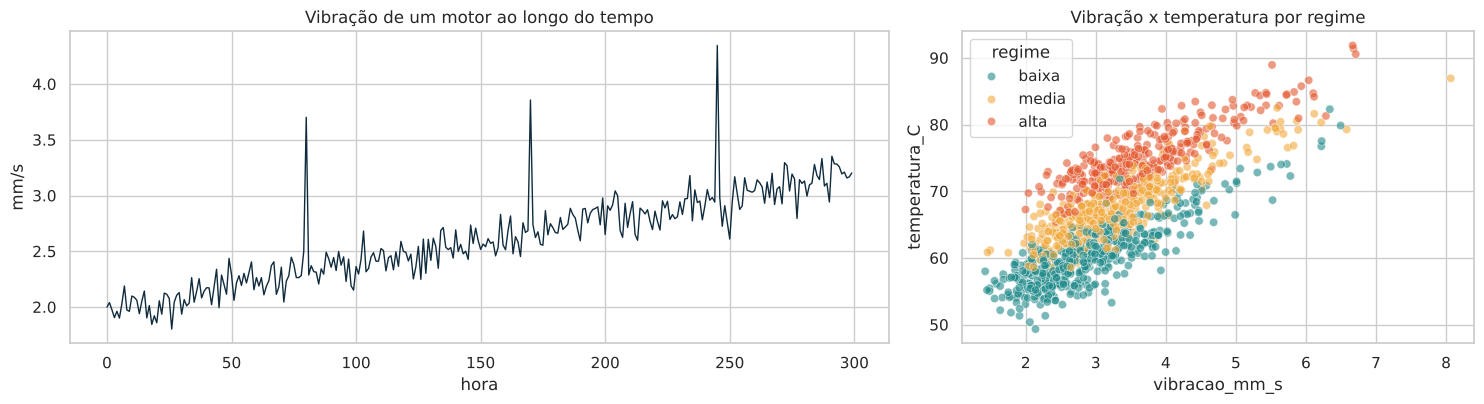

In [21]:

# Série temporal de UM motor: vibração ao longo de 300 horas
t = np.arange(300)                                           # horas 0, 1, ..., 299
rng_t = np.random.default_rng(7)
serie = pd.DataFrame({"hora": t, "vibracao": 2.0 + 0.004 * t + rng_t.normal(0, 0.12, t.size)})   # tendência de desgaste + ruído
serie["anomalia_real"] = 0                                   # coluna que marca onde injetamos picos (só para conferir)
for i in (80, 170, 245):                                     # 3 picos nas horas 80, 170 e 245
    serie.loc[i, "vibracao"] += rng_t.uniform(1.0, 1.6)
    serie.loc[i, "anomalia_real"] = 1

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(serie["hora"], serie["vibracao"], color=NAVY, lw=1)                 # a série
axes[0].set_title("Vibração de um motor ao longo do tempo"); axes[0].set_xlabel("hora"); axes[0].set_ylabel("mm/s")
sns.scatterplot(data=motores, x="vibracao_mm_s", y="temperatura_C", hue="regime",
                hue_order=["baixa", "media", "alta"], palette=[TEAL, ORANGE, RED], alpha=0.6, ax=axes[1])   # dispersão colorida pelo regime
axes[1].set_title("Vibração x temperatura por regime")
plt.tight_layout(); plt.show()


**Leitura dos gráficos** (dados de motores elétricos simulados)

- **Gráfico da esquerda, "Vibração de um motor ao longo do tempo":** horizontal = hora (0 a 300), vertical = vibração (mm/s). A linha **sobe devagar** (de cerca de 2,0 para 3,2 mm/s): é o desgaste natural. Os **3 picos** perto das horas 80, 170 e 245 são eventos anormais, e são eles que queremos detectar.
- **Gráfico da direita, "Vibração x temperatura por regime":** horizontal = vibração, vertical = temperatura (°C); cor = regime de carga (**baixa**, **média**, **alta**). A nuvem sobe para a direita: mais vibração, mais temperatura. Os regimes aparecem em camadas (alta carga no alto), mas se **sobrepõem** nas bordas, e é isso que o algoritmo vai tentar separar sem ver a coluna "regime".

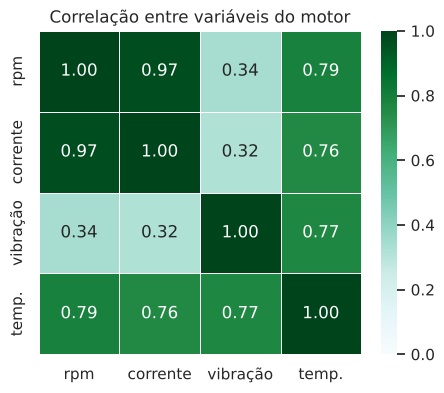

In [22]:

cols_m = ["rpm", "corrente_A", "vibracao_mm_s", "temperatura_C"]      # as 4 medidas do motor
plt.figure(figsize=(5.2, 4.2))
sns.heatmap(motores[cols_m].corr(), annot=True, fmt=".2f", cmap="BuGn", vmin=0, vmax=1, linewidths=.5,
            xticklabels=["rpm", "corrente", "vibração", "temp."], yticklabels=["rpm", "corrente", "vibração", "temp."])   # correlação entre pares
plt.title("Correlação entre variáveis do motor"); plt.show()


**Leitura do gráfico** ("Correlação entre variáveis do motor")

- **Como ler:** cada quadrado é a correlação entre duas variáveis (0 a 1 aqui; verde-escuro = andam juntas). A diagonal é sempre 1,00 (cada variável com ela mesma).
- **rpm e corrente: 0,97.** Quase a **mesma informação**: motor que gira mais puxa mais corrente. Usar as duas é redundante.
- **Temperatura:** correlaciona com rpm (**0,79**), corrente (**0,76**) e vibração (**0,77**): é a variável que "resume" o estado do motor.
- **Vibração e rpm: 0,34.** A vibração depende pouco da rotação e carrega informação **própria**, útil para achar anomalias.


### Exercício 3.3 · k-means: descobrir regimes sem rótulos
| | |
|---|---|
| **Problema** | Descobrir **quantos grupos (regimes)** existem, sem usar a coluna `regime`. |
| **Dados** | As 4 medidas do motor (rotação, corrente, vibração, temperatura), padronizadas. |
| **Modelo / técnica** | **k-means**: escolhe *k* centros, atribui cada ponto ao centro mais próximo e repete. |
| **Como medimos** | **Cotovelo** (inércia) e **silhueta** para escolher *k*; **Rand ajustado** para comparar com os regimes reais (1,0 = idênticos). |
| **O que observar** | O cotovelo sugere k = 3 (silhueta maior em k = 2: nenhuma métrica decide sozinha). Rand ajustado ≈ 0,79. |
| **Nos slides** | 45 e 56 |
| **Na apostila** | cap. 7, seção "k-means" e figura 15 |


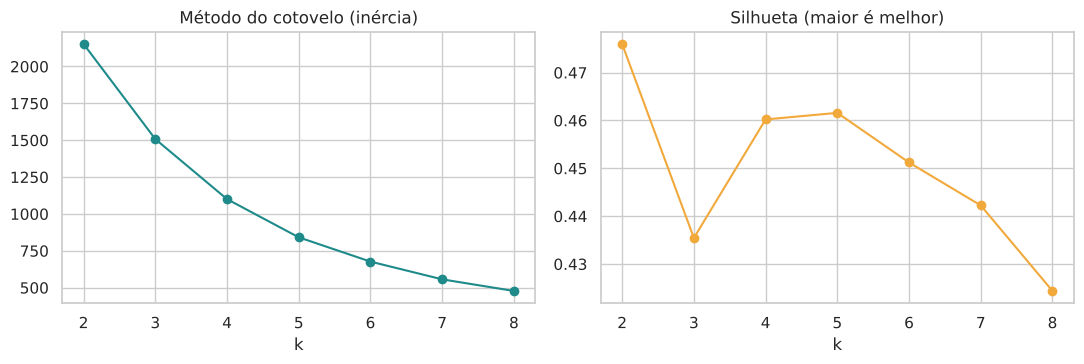

Tabela cruzada: grupo encontrado x regime verdadeiro (que o algoritmo não viu)


regime,alta,baixa,media
grupo,,,
0,0,427,11
1,0,51,375
2,311,0,25


Índice de Rand ajustado: 0.792 (1,0 = grupos idênticos aos regimes)
Silhueta com k = 3: 0.435 | Inércia: 1508

Perfil médio de cada grupo (valores originais) e taxa de falhas:


,rpm,corrente_A,vibracao_mm_s,temperatura_C,taxa_falha,n
grupo,,,,,,
0,1207.92,8.15,2.68,59.13,0.01,438
1,1726.86,11.54,3.35,67.08,0.12,426
2,2353.67,16.61,3.82,75.31,0.28,336


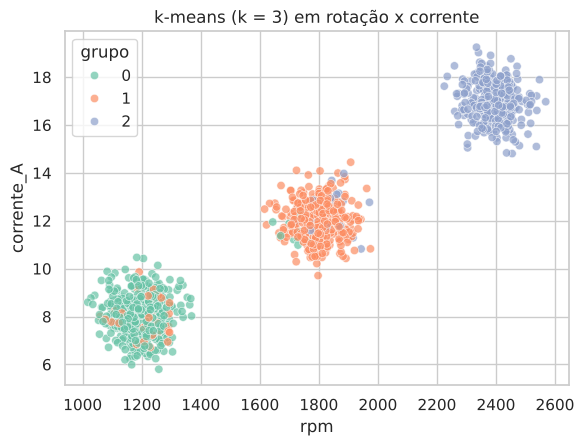

In [23]:

Xk = StandardScaler().fit_transform(motores[["rpm", "corrente_A", "vibracao_mm_s", "temperatura_C"]])   # padroniza (mesma escala)

# Testar vários valores de k (2 a 8) e medir o cotovelo (inércia) e a silhueta
ks = range(2, 9)
inercia, silh = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xk)      # treina o k-means com k grupos
    inercia.append(km_k.inertia_)                                          # quão "apertados" estão os grupos
    silh.append(silhouette_score(Xk, km_k.labels_))                        # quão separados estão os grupos

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(list(ks), inercia, "o-", color=TEAL); axes[0].set_title("Método do cotovelo (inércia)"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), silh, "o-", color=ORANGE); axes[1].set_title("Silhueta (maior é melhor)"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

# Escolhemos k = 3 (cotovelo + conhecimento do domínio: três regimes de carga)
km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xk)
motores["grupo"] = km.labels_                                              # grupo encontrado para cada leitura
print("Tabela cruzada: grupo encontrado x regime verdadeiro (que o algoritmo não viu)")
display(pd.crosstab(motores["grupo"], motores["regime"]))
print("Índice de Rand ajustado: %.3f (1,0 = grupos idênticos aos regimes)" % adjusted_rand_score(motores["regime"], motores["grupo"]))
print("Silhueta com k = 3: %.3f | Inércia: %.0f" % (silhouette_score(Xk, km.labels_), km.inertia_))   # quão bem separados e compactos
print("\nPerfil médio de cada grupo (valores originais) e taxa de falhas:")
display(motores.groupby("grupo").agg(rpm=("rpm", "mean"), corrente_A=("corrente_A", "mean"), vibracao_mm_s=("vibracao_mm_s", "mean"),
                                     temperatura_C=("temperatura_C", "mean"), taxa_falha=("falha", "mean"), n=("falha", "size")).round(2))

plt.figure(figsize=(6.5, 4.6))
sns.scatterplot(data=motores, x="rpm", y="corrente_A", hue="grupo", palette="Set2", alpha=0.7)
plt.title("k-means (k = 3) em rotação x corrente"); plt.show()


**Leitura dos gráficos** (k-means sem usar a coluna "regime")

- **Gráfico "Método do cotovelo (inércia)":** horizontal = número de grupos k, vertical = inércia (o quanto os pontos ficam longe do centro do seu grupo; menor é melhor). Ela despenca de k = 2 até 3 ou 4 e depois **cai devagar**: o "cotovelo" sugere 3 ou 4 grupos.
- **Gráfico "Silhueta":** mede quão bem separados estão os grupos (maior é melhor). O maior valor é em k = 2 (0,48), mas k = 3 (0,435) e k = 5 (0,46) são parecidos. **A escolha de k = 3 vem da engenharia**: sabemos que o motor trabalha em 3 cargas (baixa, média, alta).
- **Gráfico "k-means (k = 3) em rotação x corrente":** cada ponto é uma leitura, cor = grupo encontrado. Três nuvens bem separadas: grupo 0 (≈ 1.200 rpm e 8 A), grupo 1 (≈ 1.800 rpm e 12 A) e grupo 2 (≈ 2.400 rpm e 17 A). Os poucos pontos de cor "errada" no meio de outra nuvem são leituras em que o k-means (que usa as 4 variáveis) discordou do regime verdadeiro. O índice de Rand de **0,79** resume essa concordância (1,0 = idêntico).
- **Tabela de perfil:** o grupo de maior carga tem **28%** de falhas, contra **12%** no médio e **1%** no baixo. Os grupos descobertos têm significado na manutenção.


**Atenção ao escolher k:** a silhueta é maior com k = 2 e o cotovelo sugere 3. **Nenhuma métrica decide sozinha**: aqui o conhecimento do domínio (três regimes de carga) pesa na escolha.

**Pergunta:** que *perfil de operação* cada grupo representa? Algum grupo concentra mais falhas? (compare `motores.groupby("grupo")["falha"].mean()`)
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

Pela tabela de perfil médio (e pelo cruzamento com os regimes): o **grupo 0** é a **baixa carga** (≈ 1.208 rpm, 8,2 A, vibração 2,7 mm/s, 59 °C) com **0,9%** de falhas; o **grupo 1** é a **carga média** (≈ 1.727 rpm, 11,5 A) com **12%**; o **grupo 2** é a **alta carga** (≈ 2.354 rpm, 16,6 A, 75 °C) com **28%**. A falha **concentra-se na alta carga**: é onde a manutenção preditiva rende mais.

**Sobre k:** a silhueta (0,48 com k = 2, contra 0,44 com k = 3) prefere 2 grupos porque baixa e média carga formam uma "nuvem" contínua. O cotovelo e o conhecimento de domínio (3 regimes de carga) pesaram para escolher k = 3. **Nenhuma métrica decide sozinha.**

</details>



### Exercício 3.4 · Agrupamento hierárquico: o dendrograma
| | |
|---|---|
| **Problema** | Ver como os motores se parecem, **sem fixar o número de grupos** antes. |
| **Dados** | 18 motores sorteados entre as 1.200 leituras (para o gráfico ficar legível). |
| **Modelo / técnica** | **Agrupamento hierárquico** (método de Ward): junta os mais parecidos, passo a passo. |
| **Como medimos** | Altura do corte no **dendrograma**. |
| **O que observar** | Cortar a árvore em uma altura define o número de grupos. Motores juntos na base são muito parecidos. |
| **Nos slides** | 56 |
| **Na apostila** | seção 4.4 e figura 10 |


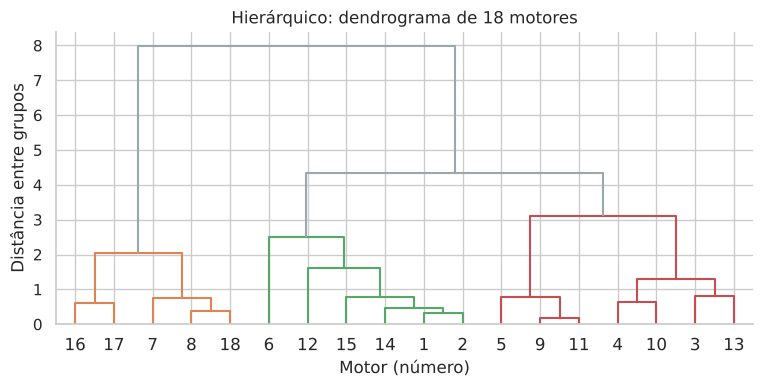

Hierárquico (3 grupos): Rand ajustado = 0.957 | silhueta = 0.434
k-means      (3 grupos): Rand ajustado = 0.792 | silhueta = 0.435


In [24]:

idx18 = np.random.default_rng(4).choice(len(Xk), 18, replace=False)      # sorteia 18 motores
L = linkage(Xk[idx18], method="ward")                                    # calcula a hierarquia de junções (método de Ward)
fig, ax = plt.subplots(figsize=(9, 3.8))
dendrogram(L, ax=ax, color_threshold=0.45 * L[:, 2].max(), above_threshold_color="#9AA7AD",
           labels=[str(i + 1) for i in range(18)])                       # desenha o dendrograma (cores = grupos ao cortar)
ax.set_title("Hierárquico: dendrograma de 18 motores"); ax.set_xlabel("Motor (número)"); ax.set_ylabel("Distância entre grupos"); limpa(ax)
plt.show()

# Métricas: o mesmo corte em 3 grupos, aplicado às 1.200 leituras
from sklearn.cluster import AgglomerativeClustering
hier = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(Xk)     # hierárquico (Ward) cortado em 3 grupos
print("Hierárquico (3 grupos): Rand ajustado = %.3f | silhueta = %.3f" % (
      adjusted_rand_score(motores["regime"], hier.labels_), silhouette_score(Xk, hier.labels_)))
print("k-means      (3 grupos): Rand ajustado = %.3f | silhueta = %.3f" % (
      adjusted_rand_score(motores["regime"], km.labels_), silhouette_score(Xk, km.labels_)))


**Leitura do gráfico** (dendrograma de 18 motores)

- **Eixos:** horizontal = número de cada motor; vertical = **distância** entre grupos no momento em que eles se juntam. Cada "U" invertido é uma fusão.
- **Como ler:** motores que se juntam **embaixo** (distância pequena, por exemplo 16 e 17) são **muito parecidos**. Quanto mais alto o "U", mais diferentes eram os grupos que se uniram.
- **Onde cortar:** uma linha horizontal entre as alturas 3,2 e 4,4 corta o gráfico em **3 grupos** (laranja, verde e vermelho). O grande salto entre as junções (4 para 8) mostra que os grupos finais são bem distintos.
- **Resultado no exercício:** com 3 grupos, o hierárquico concorda com os regimes verdadeiros (Rand **0,957**), melhor que o k-means (0,792), com silhuetas iguais (0,434 e 0,435).


**Perguntas**
1. O hierárquico teve Rand ajustado de 0,96 e o k-means de 0,79, com a mesma silhueta. Qual é "o certo"?
2. Como ler o dendrograma?

<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** Nenhum é "o certo". Os dois usam **critérios diferentes** (o k-means minimiza a distância aos centros; o Ward junta os grupos que menos aumentam a variância) e o **Rand ajustado** só mede a concordância com os regimes que **conhecemos**. Como as silhuetas são iguais (0,43), nenhuma métrica interna prefere um deles. Em dados reais não existe o gabarito `regime`: por isso se comparam métodos e se valida com o domínio.

**2.** Cada **junção** é um par de grupos que se fundem; a **altura** da junção é a distância entre eles. Motores que se juntam **baixo** são muito parecidos. **Cortar** o dendrograma em uma altura define os grupos (as cores). Saltos grandes de altura sugerem um bom ponto de corte.

</details>



### Exercício 3.5 · Isolation Forest: o que foge do padrão?
| | |
|---|---|
| **Problema** | Sinalizar as leituras de vibração **fora do padrão** (anomalias), sem ter exemplos de falha. |
| **Dados** | A série de vibração de 300 horas, com 3 picos injetados. |
| **Modelo / técnica** | **Isolation Forest**: isola observações raras com cortes aleatórios; as isoladas com poucos cortes são anomalias. `contamination=0.02` = esperamos ~2% de anomalias. |
| **Como medimos** | Quantas das 3 anomalias reais foram achadas e quantos alertas no total. |
| **O que observar** | Os 3 picos são achados, com alguns alertas a mais: é o equilíbrio entre achar tudo e gerar alarmes falsos. O algoritmo sinaliza; **a pessoa decide**. |
| **Nos slides** | 56 |
| **Na apostila** | cap. 7, seção "Isolation Forest" e figura 15 |


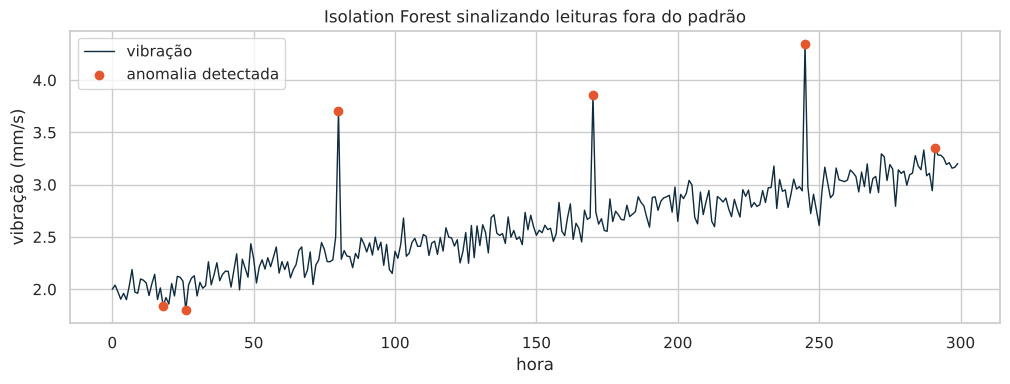

Anomalias reais: 3 | detectadas: 3 | alertas totais: 6
Sensibilidade (anomalias reais achadas) = 3/3 = 1.00
Precisão (alertas que eram anomalia real) = 3/6 = 0.50   → os outros 3 alertas são falsos alarmes


In [25]:

iso = IsolationForest(n_estimators=300, contamination=0.02, random_state=SEED)       # modelo: 300 árvores; espera ~2% de anomalias
serie["anomalia_prevista"] = (iso.fit_predict(serie[["vibracao"]]) == -1).astype(int)  # -1 = anomalia; guardamos 1 para anomalia

plt.figure(figsize=(12, 3.8))
plt.plot(serie["hora"], serie["vibracao"], color=NAVY, lw=1, label="vibração")
ev = serie[serie["anomalia_prevista"] == 1]                                          # as horas sinalizadas
plt.scatter(ev["hora"], ev["vibracao"], color=RED, zorder=3, label="anomalia detectada")
plt.legend(); plt.xlabel("hora"); plt.ylabel("vibração (mm/s)")
plt.title("Isolation Forest sinalizando leituras fora do padrão"); plt.show()

achou = int(((serie["anomalia_real"] == 1) & (serie["anomalia_prevista"] == 1)).sum())   # picos reais que foram achados
print("Anomalias reais: %d | detectadas: %d | alertas totais: %d" % (serie["anomalia_real"].sum(), achou, serie["anomalia_prevista"].sum()))
alertas = int(serie["anomalia_prevista"].sum())
print("Sensibilidade (anomalias reais achadas) = %d/%d = %.2f" % (achou, serie["anomalia_real"].sum(), achou / serie["anomalia_real"].sum()))
print("Precisão (alertas que eram anomalia real) = %d/%d = %.2f   → os outros %d alertas são falsos alarmes" % (achou, alertas, achou / alertas, alertas - achou))


**Leitura do gráfico** ("Isolation Forest sinalizando leituras fora do padrão")

- **Eixos:** horizontal = hora (0 a 300), vertical = vibração (mm/s). A linha escura é a série; os **pontos vermelhos** são as leituras que o algoritmo marcou como anomalia.
- **O que foi sinalizado:** os **3 picos reais** (horas ≈ 80, 170 e 245) foram **todos achados** (sensibilidade 3/3). Mas o modelo também marcou outros **3 pontos** (dois valores baixos perto das horas 20 a 25 e um ponto no fim da série), que são **falsos alarmes**. Precisão: 3 de 6 = **0,50**.
- **Por que isso ocorre:** definimos `contamination = 0.02`, ou seja, dissemos que cerca de 2% das leituras são anômalas, então ele sempre marca algumas. Se aumentarmos esse valor, os alertas aumentam e os 3 reais continuam achados.
- **Na engenharia:** sem nenhum exemplo de falha rotulado, o algoritmo já encontra os picos. O ajuste da contaminação é um trade-off entre perder anomalias e gerar alarmes demais.


**Perguntas**
1. O Isolation Forest achou os 3 picos, mas fez 6 alertas. Isso é bom ou ruim?
2. O que muda se você aumentar a `contamination` de 0,02 para 0,05?

<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** Sensibilidade **1,00** (3 de 3 anomalias reais) e precisão **0,50** (3 de 6 alertas eram reais): os 3 alertas extras são **falsos alarmes** (as leituras mais extremas do ruído e da tendência de desgaste). É bom para manutenção que não pode perder uma falha, mas gera trabalho de checagem. O algoritmo **sinaliza**; a pessoa decide.

**2.** `contamination` é a fração esperada de anomalias. Aumentar para 0,05 faz o modelo marcar **mais pontos** (15 em 300): a sensibilidade continua 1,00 e a **precisão cai** para 0,20 (3 de 15 alertas, 12 falsos alarmes). Com 0,01 marca só 3 pontos e, neste exemplo, os três são os picos reais (precisão 1,00); mas com dados reais, um valor baixo demais pode **deixar passar** uma anomalia. Teste na célula e compare.

</details>



### Exercício 3.6 · Resumo: três métodos não supervisionados
| | |
|---|---|
| **Problema** | Juntar as três ideias em uma figura. |
| **Dados** | Resultados dos passos 3.3, 3.4 e 3.5. |
| **Modelo / técnica** | k-means, hierárquico e Isolation Forest. |
| **Como medimos** | — |
| **O que observar** | Três perguntas, três métodos, **nenhum rótulo**: quantos regimes? como se parecem? o que foge do padrão? |
| **Nos slides** | 56 |
| **Na apostila** | seção 4.4 e figura 10 |


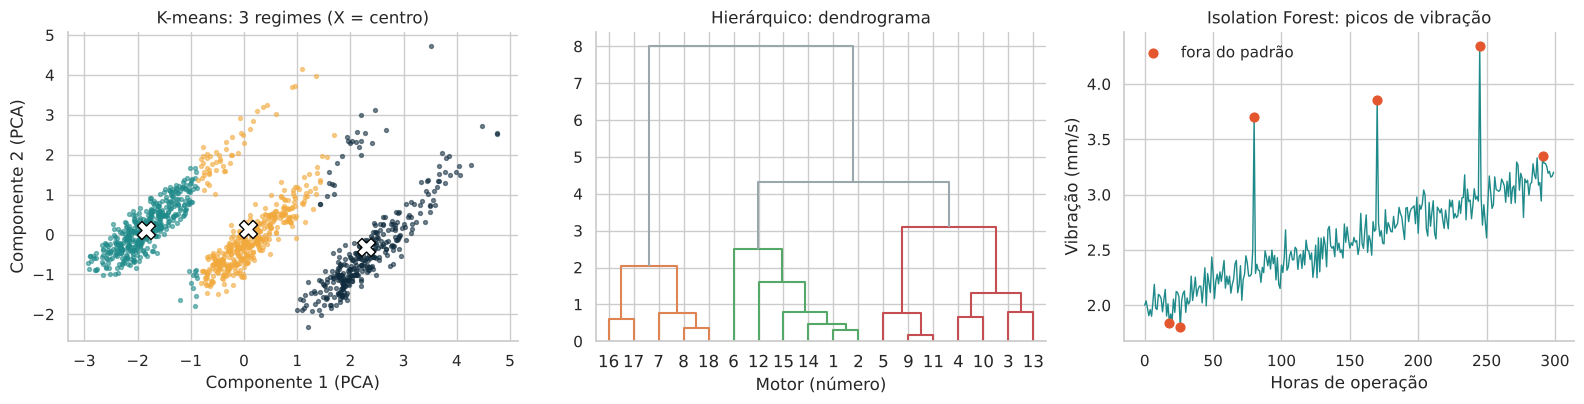

In [26]:

Zp = PCA(2, random_state=0).fit(Xk)                           # PCA só para DESENHAR os 4 sinais em 2 eixos
Q = Zp.transform(Xk); Cc = Zp.transform(km.cluster_centers_)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]                                                  # painel 1: k-means
for k_, cor_k in zip(range(3), [TEAL, ORANGE, NAVY]):
    ax.scatter(Q[km.labels_ == k_, 0], Q[km.labels_ == k_, 1], color=cor_k, s=8, alpha=.55)
ax.scatter(Cc[:, 0], Cc[:, 1], marker="X", s=170, color="white", edgecolor="black", zorder=5)   # X = centro de cada grupo
ax.set_title("K-means: 3 regimes (X = centro)"); ax.set_xlabel("Componente 1 (PCA)"); ax.set_ylabel("Componente 2 (PCA)"); limpa(ax)
dendrogram(L, ax=axes[1], color_threshold=0.45 * L[:, 2].max(), above_threshold_color="#9AA7AD",
           labels=[str(i + 1) for i in range(18)])            # painel 2: dendrograma
axes[1].set_title("Hierárquico: dendrograma"); axes[1].set_xlabel("Motor (número)"); limpa(axes[1])
ax = axes[2]                                                  # painel 3: Isolation Forest
ax.plot(serie["hora"], serie["vibracao"], color=TEAL, lw=1)
ax.scatter(ev["hora"], ev["vibracao"], color=RED, s=40, zorder=5, label="fora do padrão")
ax.set_title("Isolation Forest: picos de vibração"); ax.set_xlabel("Horas de operação"); ax.set_ylabel("Vibração (mm/s)"); ax.legend(frameon=False); limpa(ax)
plt.tight_layout(); plt.show()


**Leitura dos gráficos** (resumo dos três métodos não supervisionados)

- **Esquerda, k-means:** as leituras projetadas em dois eixos (componentes 1 e 2) e coloridas por grupo; o "X" marca o centro de um grupo. Mostra **3 regimes** de operação.
- **Centro, dendrograma:** o hierárquico mostra **como** os motores se parecem, sem fixar o número de grupos antes.
- **Direita, Isolation Forest:** a série de vibração com os pontos marcados em vermelho: **o que foge do padrão**.
- **Na engenharia:** use agrupamento para **conhecer** os regimes de operação e detecção de anomalias para **vigiar** o que sai do comum.


---
## Bloco 4 · Engenharia Mecânica: diagnóstico de rolamentos por vibração
**Onde implementar:** em bombas, ventiladores, redutores e máquinas rotativas. Um acelerômetro mede a vibração; extraímos poucas **características** (RMS, curtose, fator de crista, energia nas frequências de falha) e o modelo diz se o rolamento está **saudável** ou com falha na **pista externa** ou **interna**.

*Resumo do bloco:* dados (4.1) → PCA para visualizar (4.2) → SVM (4.3). Apostila: **capítulo 8** e **seção 4.5**.

Com 6 variáveis não dá para olhar um gráfico só. O **PCA** resume as variáveis em 2 eixos para *enxergar* as classes.



### Exercício 4.1 · Criar os dados (simulados)
| | |
|---|---|
| **Problema** | Dizer a **condição do rolamento**: saudável, falha na pista externa ou falha na pista interna. |
| **Dados** | 900 observações (300 de cada condição) com 6 características de vibração: RMS, curtose, fator de crista, energia BPFO, energia BPFI e temperatura. |
| **Modelo / técnica** | Ainda não há modelo. |
| **Como medimos** | — |
| **O que observar** | As médias de cada característica por condição: as falhas aumentam RMS, curtose e fator de crista, e a energia na banda da pista com defeito. |
| **Nos slides** | 57 e 58 |
| **Na apostila** | cap. 8, seção "Os dados (simulados)" |


In [27]:

rng = np.random.default_rng(SEED)
# (média, desvio) de cada característica por condição: rms, curtose, fator de crista, energia BPFO, energia BPFI, temperatura
perfil = {
    "saudável":      [(0.65, .15), (3.4, .7), (3.9, .6), (0.04, .025), (0.04, .025), (57, 5)],
    "pista externa": [(0.90, .20), (4.3, .9), (4.8, .8), (0.20, .100), (0.08, .050), (60, 5)],
    "pista interna": [(1.00, .22), (4.6, 1.0), (5.0, .9), (0.10, .060), (0.22, .100), (61, 5)],
}
cols = ["rms_g", "curtose", "fator_crista", "energia_BPFO", "energia_BPFI", "temperatura_C"]   # nomes das 6 colunas
linhas = []
for cond, params in perfil.items():                       # para cada condição do rolamento...
    for _ in range(300):                                  # ...sorteia 300 observações
        v = [abs(rng.normal(m, s)) if c.startswith("energia") else rng.normal(m, s)
             for c, (m, s) in zip(cols, params)]          # energia não pode ser negativa (abs)
        linhas.append(v + [cond])
rolamentos = pd.DataFrame(linhas, columns=cols + ["condicao"])
print(rolamentos.shape); display(rolamentos.sample(5, random_state=SEED).round(2))   # 5 linhas ao acaso
display(rolamentos.groupby("condicao")[cols].mean().round(2))                        # média por condição


(900, 7)


,rms_g,curtose,fator_crista,energia_BPFO,energia_BPFI,temperatura_C,condicao
70,0.66,2.81,3.54,0.00,0.02,55.21,saudável
827,1.06,4.11,4.42,0.11,0.18,55.45,pista interna
231,0.84,2.64,4.10,0.02,0.02,64.39,saudável
588,0.59,4.20,6.05,0.18,0.15,61.76,pista externa
39,0.54,2.94,2.61,0.04,0.01,54.35,saudável


,rms_g,curtose,fator_crista,energia_BPFO,energia_BPFI,temperatura_C
condicao,,,,,,
pista externa,0.91,4.27,4.77,0.20,0.09,59.95
pista interna,1.00,4.51,4.94,0.11,0.22,60.98
saudável,0.63,3.36,3.88,0.04,0.04,56.77



### Exercício 4.2 · Visualizar com PCA: 6 dimensões em 2
| | |
|---|---|
| **Problema** | **Enxergar** as 3 condições em um gráfico, mesmo com 6 variáveis. |
| **Dados** | As 900 observações (75% treino, 25% teste, com `stratify`). |
| **Modelo / técnica** | **PCA**: combina as 6 variáveis em eixos novos (componentes), ordenados pela variância que guardam. Ajustado **só com o treino** (evita vazamento de dados). |
| **Como medimos** | Variância explicada por componente. |
| **O que observar** | O 1º eixo guarda 37,6% e o 2º 15,6% (53% juntos): já separa o rolamento saudável das falhas. |
| **Nos slides** | 46 e 58 |
| **Na apostila** | seção 4.5 e figura 11; cap. 8 |


Variância explicada por componente: [37.6 15.6 14.8 11.9 11.2  8.8] %


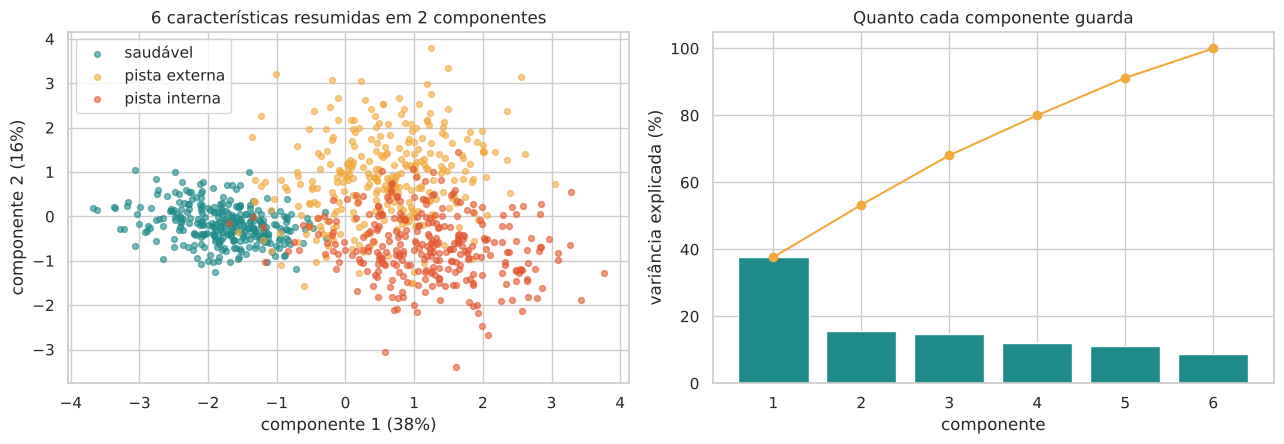

In [28]:

Xm = rolamentos[cols]; ym = rolamentos["condicao"]                    # entradas (6 colunas) e classe
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.25, stratify=ym, random_state=SEED)

# O PCA é ajustado SÓ com o treino (evita vazamento de dados)
pca_mec = make_pipeline(StandardScaler(), PCA(random_state=SEED)).fit(Xm_tr)    # padroniza e calcula os componentes
var = pca_mec[-1].explained_variance_ratio_                                     # fração da variância de cada componente
print("Variância explicada por componente:", (100 * var).round(1), "%")

Z = pca_mec.transform(Xm)[:, :2]                                      # projeta todas as observações nos 2 primeiros eixos
cores = {"saudável": TEAL, "pista externa": ORANGE, "pista interna": RED}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for cond, cor in cores.items():
    idx = (ym == cond).values
    axes[0].scatter(Z[idx, 0], Z[idx, 1], s=18, alpha=0.6, color=cor, label=cond)    # cada condição com uma cor
axes[0].set_xlabel("componente 1 (%.0f%%)" % (100 * var[0])); axes[0].set_ylabel("componente 2 (%.0f%%)" % (100 * var[1]))
axes[0].set_title("6 características resumidas em 2 componentes"); axes[0].legend()
axes[1].bar(range(1, 7), 100 * var, color=TEAL); axes[1].plot(range(1, 7), 100 * np.cumsum(var), "o-", color=ORANGE)   # barras + acumulado
axes[1].set_xlabel("componente"); axes[1].set_ylabel("variância explicada (%)"); axes[1].set_title("Quanto cada componente guarda")
plt.tight_layout(); plt.show()


**Leitura dos gráficos** (900 observações de rolamentos, 6 características de vibração cada)

- **Gráfico da esquerda (projeção PCA):** o PCA combina as 6 variáveis em 2 eixos novos para podermos desenhar. Horizontal = componente 1 (guarda **38%** da informação), vertical = componente 2 (**16%**). Cada ponto é um rolamento: **verde** = saudável, **laranja** = falha na pista externa, **vermelho** = falha na pista interna.
- **O que se vê:** os **saudáveis** ficam bem à esquerda, separados dos defeituosos. As duas falhas ocupam a direita e se **sobrepõem** um pouco, são mais difíceis de distinguir entre si.
- **Gráfico da direita (variância explicada):** cada barra é a informação guardada por um componente (37,6%; 15,6%; 14,8%; 11,9%; 11,2%; 8,8%) e a linha laranja é a soma acumulada. Dois componentes guardam só cerca de **53%**, e três, cerca de **68%**: reduzir para 2 dimensões **perde informação**, e vamos medir quanto no exercício seguinte.


### Exercício 4.3 · Classificar: SVM com todas as variáveis x SVM depois do PCA
| | |
|---|---|
| **Problema** | Classificar a condição do rolamento e medir **o que se perde** ao reduzir de 6 para 2 ou 3 componentes. |
| **Dados** | As mesmas observações, com a divisão treino/teste do passo anterior. |
| **Modelo / técnica** | **SVM** (kernel RBF) com 6 variáveis, após PCA de 2 e de 3 componentes; **Random Forest** para comparar. |
| **Como medimos** | Acurácia no teste e **matriz de confusão**. |
| **O que observar** | SVM com 6 variáveis: 92,4%. PCA de 2 componentes: 86,7%. De 3: 90,7%. O PCA ajuda a enxergar, mas reduzir dimensões perde informação. |
| **Nos slides** | 58 |
| **Na apostila** | cap. 8, seção "Classificar" e figura 16 |


,Acurácia no teste
Modelo,
SVM (6 variáveis),0.924
SVM após PCA (2 comp.),0.867
SVM após PCA (3 comp.),0.907
Random Forest,0.920


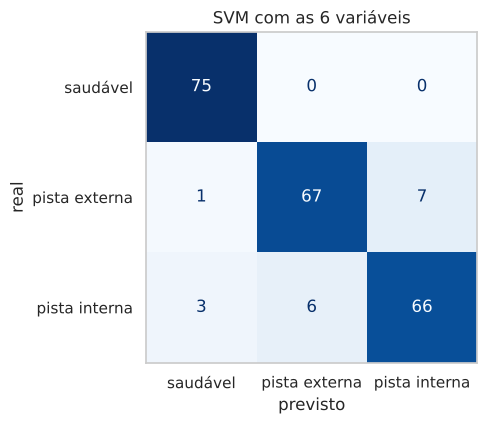

               precision    recall  f1-score   support

pista externa      0.918     0.893     0.905        75
pista interna      0.904     0.880     0.892        75
     saudável      0.949     1.000     0.974        75

     accuracy                          0.924       225
    macro avg      0.924     0.924     0.924       225
 weighted avg      0.924     0.924     0.924       225



In [29]:

modelos_mec = {
    "SVM (6 variáveis)": make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=SEED)),                       # usa as 6 variáveis
    "SVM após PCA (2 comp.)": make_pipeline(StandardScaler(), PCA(n_components=2), SVC(kernel="rbf", random_state=SEED)),   # resume em 2 e classifica
    "SVM após PCA (3 comp.)": make_pipeline(StandardScaler(), PCA(n_components=3), SVC(kernel="rbf", random_state=SEED)),   # resume em 3
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),                                     # para comparar
}
res = []
for nome, m in modelos_mec.items():
    m.fit(Xm_tr, ym_tr)                                                         # treina
    res.append({"Modelo": nome, "Acurácia no teste": accuracy_score(ym_te, m.predict(Xm_te))})   # mede no teste
tab_mec = pd.DataFrame(res).set_index("Modelo").round(3)
display(tab_mec)

ordem = ["saudável", "pista externa", "pista interna"]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
matriz(ym_te, modelos_mec["SVM (6 variáveis)"].predict(Xm_te), ax, ordem, titulo="SVM com as 6 variáveis")   # onde o SVM erra
plt.tight_layout(); plt.show()

# Métricas por classe do SVM (6 variáveis): precisão, sensibilidade e F1 de cada condição
from sklearn.metrics import classification_report
print(classification_report(ym_te, modelos_mec["SVM (6 variáveis)"].predict(Xm_te), digits=3))


**Leitura do gráfico** (matriz de confusão do SVM com as 6 variáveis, 225 rolamentos de teste: 75 de cada condição)

- **Como ler:** linhas = condição real; colunas = condição prevista; a diagonal são os acertos.
- **Saudável:** 75 de 75 certos. Nenhum rolamento saudável foi condenado.
- **Pista externa:** 67 certos, 1 confundido com saudável e **7 confundidos com pista interna**.
- **Pista interna:** 66 certos, 3 confundidos com saudável e **6 com pista externa**.
- **Conclusão:** acurácia de **92,4%** ((75 + 67 + 66)/225). Os erros se concentram entre as **duas falhas** (13 casos) e confirmam o que o PCA mostrou: elas se parecem. Em manutenção, o pior erro é confundir falha com saudável (4 casos).
- **O efeito do PCA (tabela acima):** SVM com as 6 variáveis **92,4%**; após PCA de 3 componentes, **90,7%**; de 2 componentes, **86,7%**; Random Forest, **92,0%**. Reduzir dimensão custa um pouco de acerto, mas facilita visualizar e explicar.


**Perguntas**
1. O que se perde ao reduzir de 6 para 2 componentes? E ao usar 3?
2. Quais classes o modelo mais confunde? Por que as duas falhas se parecem mais entre si do que com o rolamento saudável?
3. Em manutenção, é pior classificar uma falha como saudável ou um saudável como falha?
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** Ao resumir em **2 componentes**, a acurácia cai de 92,4% para 86,7% (perda de ~6 pontos); com **3**, para 90,7%. Os componentes 3 a 6 guardam 47% da variância (100 − 37,6 − 15,6) e parte dessa informação ajuda a separar as classes: **reduzir dimensões sempre perde informação**. O PCA é ótimo para **enxergar**, não necessariamente para melhorar o classificador.

**2.** O relatório por classe mostra: **saudável** tem sensibilidade 1,00 e precisão 0,95; as duas falhas ficam em ≈ 0,88 a 0,89 de sensibilidade. As **duas falhas se confundem entre si** porque ambas elevam RMS, curtose e fator de crista de forma parecida: só diferem em **qual banda de frequência** (BPFO ou BPFI) concentra a energia. Em relação ao saudável, ambas ficam longe.

**3.** Em geral, **falha classificada como saudável** é mais grave: a máquina continua rodando e pode quebrar sem aviso (parada não planejada). Saudável classificado como falha gera uma **inspeção desnecessária**. Por isso, em manutenção, costuma-se priorizar a **sensibilidade** para falhas (o mesmo raciocínio do limiar na Produção).

</details>



---
## Bloco 5 · Engenharia Química: concentração a partir de espectros (sensor virtual)
**Onde implementar:** em reatores e linhas de processo com **espectroscopia NIR** em linha. Medir a concentração por análise de laboratório é lento; o espectro é imediato. Um modelo converte o **espectro (120 variáveis)** em **concentração**, permitindo controle em tempo real.

*Resumo do bloco:* dados e espectros (5.1) → PCA (5.2) → regressão (5.3). Apostila: **capítulo 9**.

**Desafio:** os picos de A, B e C se sobrepõem, e há deriva de linha de base. As 120 variáveis são muito correlacionadas, e o PCA ajuda a resumi-las.



### Exercício 5.1 · Criar e visualizar os espectros (simulados)
| | |
|---|---|
| **Problema** | Estimar a **concentração do analito A (%)** a partir do espectro da amostra. |
| **Dados** | 220 espectros com 120 comprimentos de onda (1100 a 2300 nm). Três substâncias (A, B, C) com picos sobrepostos, deriva de linha de base e ruído. |
| **Modelo / técnica** | Ainda não há modelo. |
| **Como medimos** | — |
| **O que observar** | Cada curva é uma amostra; a cor mostra a concentração de A. Os picos de A e B se misturam: não dá para ler a concentração "a olho". |
| **Nos slides** | 59 e 60 |
| **Na apostila** | cap. 9, seção "Os dados (simulados)" e figura 17 |


In [30]:

rng = np.random.default_rng(SEED)
n = 220                                                       # número de amostras
comprimento = np.linspace(1100, 2300, 120)                    # 120 comprimentos de onda, em nm
pico = lambda centro, larg: np.exp(-0.5 * ((comprimento - centro) / larg) ** 2)   # forma de um pico (curva em sino)

A = rng.uniform(0, 10, n)     # concentração do analito de interesse (%)  <- é o que queremos prever
B = rng.uniform(0, 10, n)     # interferente 1
Cc = rng.uniform(0, 10, n)    # interferente 2

espectro = (A[:, None] * 0.10 * pico(1450, 45) + B[:, None] * 0.09 * pico(1530, 55)
            + Cc[:, None] * 0.08 * pico(1930, 60))            # espectro = soma dos picos de A, B e C (proporcionais às concentrações)
deriva = rng.normal(0.5, 0.15, (n, 1)) + rng.normal(0, 0.00015, (n, 1)) * (comprimento - 1700)   # linha de base que varia
S = espectro + deriva + rng.normal(0, 0.03, (n, comprimento.size))   # espectro medido = sinal + deriva + ruído
print("Espectros:", S.shape, "(amostras x comprimentos de onda)")


Espectros: (220, 120) (amostras x comprimentos de onda)


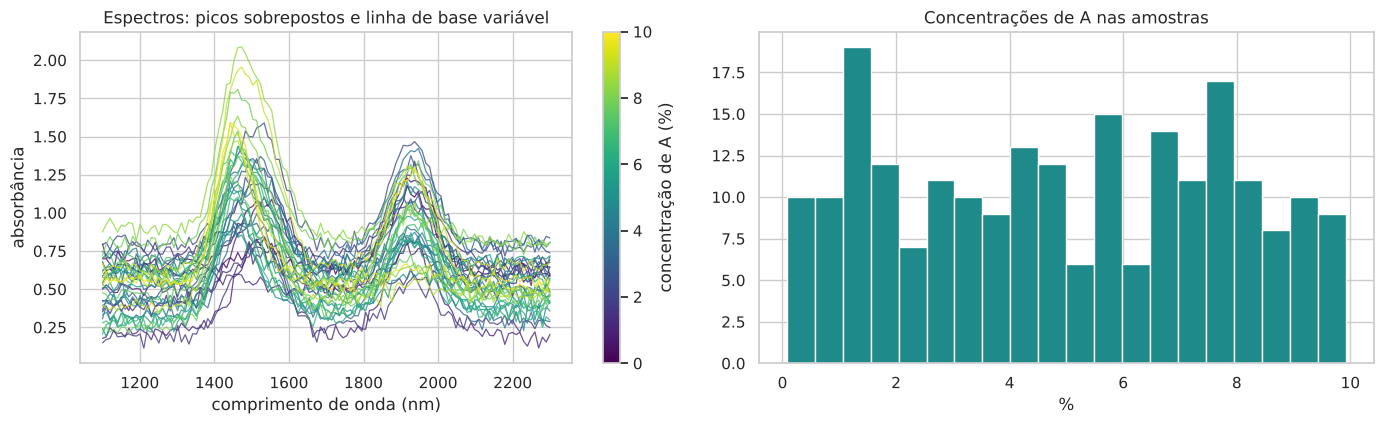

In [31]:

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
cmap = plt.cm.viridis
for i in np.argsort(A)[::6]:                                  # desenha 1 a cada 6 espectros, em ordem de concentração
    axes[0].plot(comprimento, S[i], color=cmap(A[i] / 10), lw=0.9, alpha=0.8)      # cor = concentração de A
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 10)); plt.colorbar(sm, ax=axes[0]).set_label("concentração de A (%)")
axes[0].set_xlabel("comprimento de onda (nm)"); axes[0].set_ylabel("absorbância"); axes[0].set_title("Espectros: picos sobrepostos e linha de base variável")
axes[1].hist(A, bins=20, color=TEAL); axes[1].set_title("Concentrações de A nas amostras"); axes[1].set_xlabel("%")   # histograma
plt.tight_layout(); plt.show()


**Leitura dos gráficos** (220 espectros simulados; queremos estimar a **concentração da substância A (%)** de cada amostra)

- **Gráfico da esquerda, "Espectros":** horizontal = comprimento de onda (nm), vertical = absorbância (quanta luz a amostra absorve). Cada linha é uma amostra. Há dois **picos** (por volta de 1.450 e 1.930 nm), e a **cor** indica a concentração de A: linhas **amarelas** (A alta) têm picos **mais altos**, e linhas roxas (A baixa) têm picos baixos. A altura da linha de base varia de amostra para amostra (um defeito do instrumento) e os picos de outras substâncias se sobrepõem, então o valor de A **não** se lê direto em um único ponto.
- **Gráfico da direita, "Concentrações de A nas amostras":** horizontal = % de A (0 a 10), vertical = número de amostras. Os valores se espalham de forma razoavelmente uniforme, o que é bom para treinar (cobre toda a faixa).
- **Na engenharia:** é a ideia de **sensor virtual**: em vez de um ensaio de laboratório demorado, o espectro (rápido) é usado para estimar a concentração.


### Exercício 5.2 · PCA: quantos componentes bastam?
| | |
|---|---|
| **Problema** | Resumir as **120 variáveis** do espectro em poucos componentes, mantendo a informação necessária para prever a **concentração de A (%)**. |
| **Dados** | Os 220 espectros: 70% treino e 30% teste. |
| **Modelo / técnica** | **PCA** ajustado só no treino. |
| **Como medimos** | Variância acumulada (critério usual: 95%). |
| **O que observar** | 4 componentes explicam 95,4% da variância. Mas veremos que 5 dão o menor erro. |
| **Nos slides** | 46 e 60 |
| **Na apostila** | cap. 9, seção "PCA: quantos componentes bastam?" e figura 17 |


4 componentes explicam 95.4% da variância (de 120 variáveis)


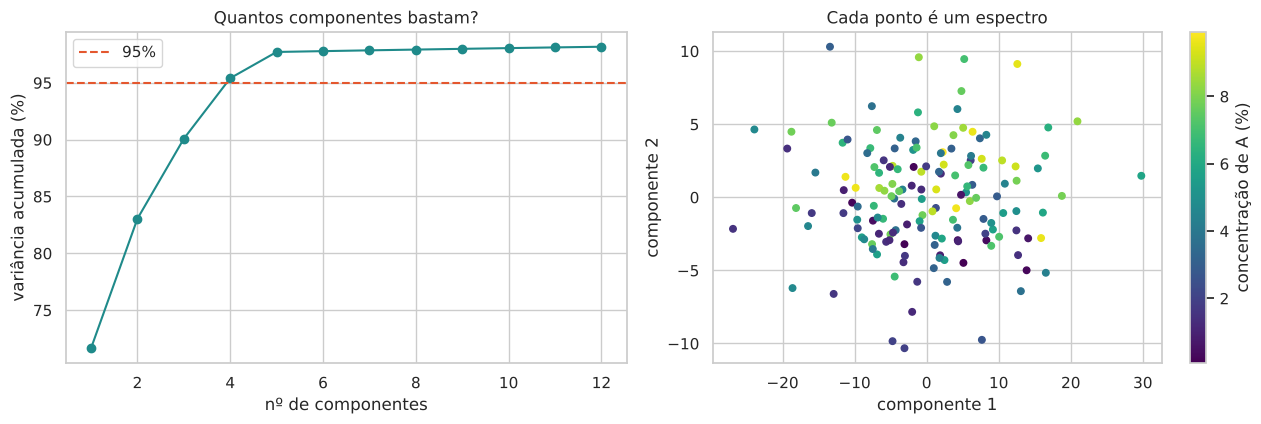

In [32]:

S_tr, S_te, A_tr, A_te = train_test_split(S, A, test_size=0.3, random_state=SEED)    # treino (70%) e teste (30%)

pca_q = make_pipeline(StandardScaler(), PCA(random_state=SEED)).fit(S_tr)   # padroniza e calcula o PCA com o treino
var_q = pca_q[-1].explained_variance_ratio_                                 # variância de cada componente
acum = np.cumsum(var_q)                                                     # variância acumulada
n95 = int(np.argmax(acum >= 0.95) + 1)                                      # nº de componentes para chegar a 95%
print("%d componentes explicam %.1f%% da variância (de %d variáveis)" % (n95, 100 * acum[n95 - 1], S.shape[1]))

T = pca_q.transform(S_tr)                                                   # espectros projetados nos componentes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(range(1, 13), 100 * acum[:12], "o-", color=TEAL); axes[0].axhline(95, color=RED, ls="--", label="95%")
axes[0].set_xlabel("nº de componentes"); axes[0].set_ylabel("variância acumulada (%)"); axes[0].set_title("Quantos componentes bastam?"); axes[0].legend()
sc = axes[1].scatter(T[:, 0], T[:, 1], c=A_tr, cmap="viridis", s=22)        # cada ponto é um espectro; cor = concentração
plt.colorbar(sc, ax=axes[1]).set_label("concentração de A (%)")
axes[1].set_xlabel("componente 1"); axes[1].set_ylabel("componente 2"); axes[1].set_title("Cada ponto é um espectro")
plt.tight_layout(); plt.show()


**Leitura dos gráficos**

- **Gráfico da esquerda, "Quantos componentes bastam?":** horizontal = número de componentes do PCA, vertical = variância acumulada (%). A linha tracejada vermelha marca 95%. Com **1 componente** já temos cerca de 72%; **4 componentes** chegam a **95,4%** (cruzam a linha) e **5** passam de 97%. As 120 variáveis originais cabem em poucos componentes.
- **Gráfico da direita, "Cada ponto é um espectro":** horizontal = componente 1, vertical = componente 2; **cor** = concentração de A. As cores aparecem **misturadas**: com só 2 componentes não dá para ver a concentração. A informação sobre A está em componentes além dos 2 primeiros, e é por isso que precisamos de 4 ou 5 no modelo.


### Exercício 5.3 · Regressão: 120 variáveis x PCA
| | |
|---|---|
| **Problema** | Prever a concentração de A com o **menor erro**. |
| **Dados** | Espectros de treino e teste do passo anterior. |
| **Modelo / técnica** | **Regressão linear** nos 120 comprimentos de onda; **regressão após PCA** (PCR) com 4 e 5 componentes; **Random Forest**. |
| **Como medimos** | MAE (em % de concentração) e R². |
| **O que observar** | PCA com **5 componentes** erra menos (MAE ≈ 0,12%, R² ≈ 0,997). Com 4 o erro explode (1,78%), embora a regra dos 95% sugerisse 4: **variância explicada não é tudo**. |
| **Nos slides** | 60 |
| **Na apostila** | cap. 9 e figura 17 |


,MAE (%),RMSE (%),R²
Modelo,,,
Linear (120 variáveis),0.268,0.332,0.986
PCA (4 comp.) + linear,1.779,2.184,0.398
PCA (5 comp.) + linear,0.117,0.144,0.997
Random Forest,0.548,0.689,0.940


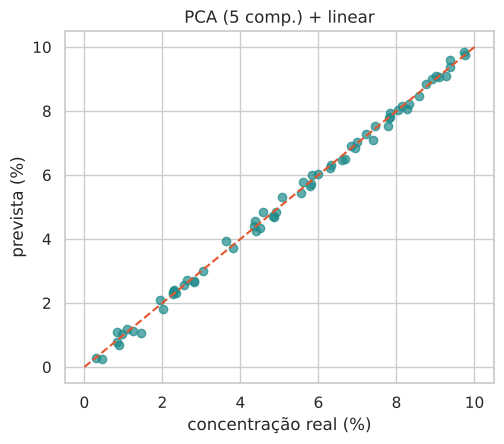

In [33]:

modelos_q = {
    "Linear (120 variáveis)": LinearRegression(),                                                    # usa todos os comprimentos de onda
    "PCA (4 comp.) + linear": make_pipeline(StandardScaler(), PCA(n_components=4), LinearRegression()),   # resume em 4 e faz regressão
    "PCA (5 comp.) + linear": make_pipeline(StandardScaler(), PCA(n_components=5), LinearRegression()),   # resume em 5
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=SEED),
}
res = []; prev_q = {}
for nome, m in modelos_q.items():
    m.fit(S_tr, A_tr); prev_q[nome] = m.predict(S_te)             # treina e prevê a concentração
    res.append({"Modelo": nome, "MAE (%)": mean_absolute_error(A_te, prev_q[nome]),
                "RMSE (%)": np.sqrt(np.mean((A_te - prev_q[nome]) ** 2)), "R²": r2_score(A_te, prev_q[nome])})
tab_q = pd.DataFrame(res).set_index("Modelo").round(3)
display(tab_q)

melhor = "PCA (5 comp.) + linear"                                  # o melhor modelo
plt.figure(figsize=(5.2, 4.6))
plt.scatter(A_te, prev_q[melhor], color=TEAL, alpha=0.7)           # previsto x real
plt.plot([0, 10], [0, 10], "--", color=RED); plt.xlabel("concentração real (%)"); plt.ylabel("prevista (%)")
plt.title(melhor); plt.tight_layout(); plt.show()


**Leitura do gráfico e da tabela**

- **Gráfico "PCA (5 comp.) + linear":** horizontal = concentração **real** de A (%), vertical = concentração **prevista**. A linha tracejada vermelha é a previsão perfeita. Os pontos ficam **praticamente sobre a linha**: erro médio de apenas **0,117 pontos percentuais** e R² de **0,997**.
- **Comparação (tabela acima, no teste):** **PCA 5 + linear**: MAE 0,117, R² 0,997 (melhor). **Linear com 120 variáveis**: MAE 0,268, R² 0,986 (bom, mas usa tudo e é mais sensível ao ruído). **Random Forest**: MAE 0,548, R² 0,940. **PCA 4 + linear**: MAE **1,779**, R² **0,398**, ou seja, com 4 componentes (95,4% da variância) o modelo **piora muito**.
- **Lição:** "explicar 95% da variância" não garante que a informação do **alvo** esteja ali. Teste o número de componentes pela métrica de previsão (MAE e R²), não só pela variância.


**Perguntas**
1. O critério dos **95% de variância** sugeriu 4 componentes, mas **5** deram o menor erro. Por que a variância explicada não é tudo? O que são esses 5 eixos fisicamente? (dica: 3 substâncias + linha de base)
2. Qual a vantagem de reduzir antes de regredir quando há mais variáveis do que amostras?
3. Onde estaria a incerteza em um sensor virtual instalado na planta? (calibração, deriva, nova matéria-prima)
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** Os 4 primeiros componentes já cobrem 95% da variância, mas essa variância é dominada pelos **picos fortes** (A, B e C sobrepostos). O **5º eixo**, com pouca variância, é o que **separa a contribuição de A da de B** (picos que se sobrepõem) e corrige a linha de base: informação decisiva para prever A. Por isso, com 4 componentes o MAE é 1,78% e com 5 cai para 0,12%. Fisicamente, os eixos correspondem a **3 substâncias + a linha de base** (+ ruído). **Variância explicada não é o mesmo que informação útil para o alvo**: valide o número de componentes (por exemplo, por validação cruzada).

**2.** Com 120 variáveis e só 154 amostras de treino, as variáveis são **muito correlacionadas** e a regressão sofre com colinearidade e tende a **sobreajustar**. O PCA resume em poucas variáveis **independentes**, mais estáveis e com menos ruído. (Aqui a regressão linear nas 120 variáveis ainda foi bem, R² 0,986, mas o PCR com 5 componentes foi melhor: 0,997.)

**3.** A incerteza vem de: **calibração** do espectrômetro, **deriva** da linha de base ao longo do tempo, **nova matéria-prima** com picos diferentes, temperatura e entupimento da sonda, e amostras **fora da faixa de concentração** usada no treino. Em campo, mantenha **checagens periódicas com o laboratório** e retreine quando necessário.

</details>



---
## Fechamento
Apostila: **capítulo 10** (quadro-resumo) e **capítulo 11** (cuidados).

### Quadro-resumo: uma técnica para cada pergunta
| Engenharia | Pergunta | Técnica | Principal métrica |
|---|---|---|---|
| Civil | Qual a resistência? | Regressão (linear, Random Forest) | MAE, R² |
| Produção | A peça terá defeito? | Classificação (árvore, floresta) | sensibilidade, precisão, especificidade, ROC/AUC |
| Elétrica | Quais perfis e anomalias? | k-means, hierárquico, Isolation Forest | silhueta, Rand ajustado, alertas |
| Mecânica | Qual a condição do rolamento? | PCA + SVM | acurácia, matriz de confusão |
| Química | Qual a concentração? | PCA + regressão | MAE, R² |

### Pipeline que se repete em toda engenharia
**Dados → separar treino e teste → treinar → medir no teste → decidir com responsabilidade.**


In [34]:

# Tabela final com o resultado de cada engenharia (os números vêm das células anteriores)
resumo = pd.DataFrame({
    "Engenharia": ["Civil", "Produção", "Elétrica", "Mecânica", "Química"],
    "Resultado no teste": [
        "Random Forest: MAE %.2f MPa, R² %.3f" % (tab_civil.loc["Random Forest", "MAE (MPa)"], tab_civil.loc["Random Forest", "R²"]),
        "Random Forest: recall %.2f, precisão %.2f" % (tab_prod.loc["Random Forest", "Recall (defeitos achados)"], tab_prod.loc["Random Forest", "Precisão (alertas certos)"]),
        "k-means: Rand ajustado %.2f; Isolation Forest: %d de %d anomalias" % (adjusted_rand_score(motores["regime"], motores["grupo"]), achou, serie["anomalia_real"].sum()),
        "SVM: acurácia %.2f" % tab_mec.loc["SVM (6 variáveis)", "Acurácia no teste"],
        "PCA (5 comp.) + linear: MAE %.2f %%, R² %.3f" % (tab_q.loc["PCA (5 comp.) + linear", "MAE (%)"], tab_q.loc["PCA (5 comp.) + linear", "R²"]),
    ]})
display(resumo)


,Engenharia,Resultado no teste
0,Civil,"Random Forest: MAE 2.16 MPa, R² 0.962"
1,Produção,"Random Forest: recall 0.74, precisão 0.74"
2,Elétrica,k-means: Rand ajustado 0.79; Isolation Forest:...
3,Mecânica,SVM: acurácia 0.92
4,Química,"PCA (5 comp.) + linear: MAE 0.12 %, R² 0.997"



### Desafio final (escolha um)
1. **Civil:** altere o intervalo de idade (só 3 e 7 dias) e veja o erro. Dá para prever a resistência aos 28 dias com ensaios precoces?
2. **Produção:** varie o limiar do Random Forest e escolha o ideal para peças de segurança.
3. **Elétrica:** mude `contamination` do Isolation Forest (0,01; 0,02; 0,05) e discuta falsos alarmes.
4. **Mecânica:** acrescente ruído às características e veja quando o SVM deixa de separar as classes.
5. **Química:** aumente o ruído do espectro e encontre o número de componentes do PCA que dá o menor erro (use validação cruzada).
6. **Seus dados:** substitua os dados simulados por um CSV do seu laboratório e repita o fluxo.

> **Cuidados** (apostila, cap. 11): **qualidade** dos dados, **vazamento** de dados, **viés**, **validação** em dados independentes, **privacidade** e **supervisão** humana. Os dados deste notebook são **didáticos**.

> **Extras (fora da aula):** Bônus A (imagens de folhas e Teachable Machine) e Bônus B (alerta no n8n), logo abaixo.



---
## Bônus A (extra): imagens, folhas com sintoma de *greening*
A palestra começa com **imagens** (folhas de citros e o *Teachable Machine*). Aqui está a versão em código, como **atividade extra**. Apostila: **capítulo 13**.



### Bônus A · Folhas sintéticas e atributos de imagem
| | |
|---|---|
| **Problema** | Classificar uma folha como **sadia** ou **com sintoma** (amarelado irregular, parecido com o *greening*). |
| **Dados** | 240 folhas **sintéticas** geradas no código (120 sadias e 120 com sintoma), com variação de iluminação e sintomas de intensidade variável. Com fotos reais, o passo a passo é o mesmo, mas o desafio é maior. |
| **Modelo / técnica** | Extraímos **16 atributos** por imagem (média e desvio de R, G, B e o histograma de textura **LBP**) e classificamos com **Random Forest**. |
| **Como medimos** | Acurácia, sensibilidade (sintoma achado) e especificidade no teste. |
| **O que observar** | O modelo acerta cerca de 86%: o problema não é trivial, e os atributos de cor e textura mais usados aparecem no gráfico da direita. |
| **Nos slides** | 27 a 32 (exemplo das folhas e Teachable Machine) |
| **Na apostila** | cap. 13 |



**Ideia:** uma foto é uma tabela de números (pixels). Em vez de dar a imagem inteira ao modelo, extraímos poucos **atributos** de **cor** e de **textura** (o *Local Binary Pattern*, LBP, compara cada pixel com seus vizinhos). Depois o fluxo é o de sempre.


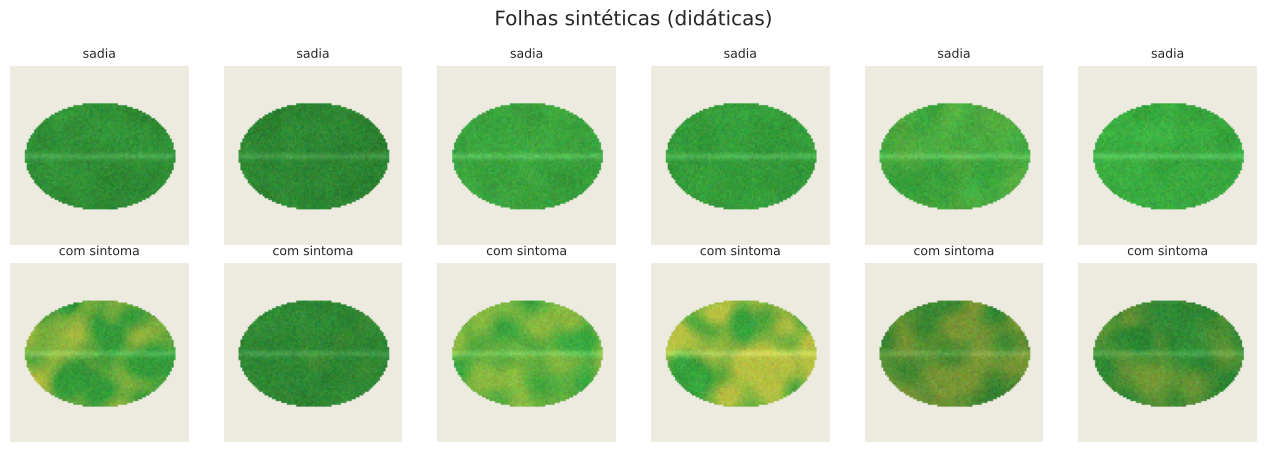

In [35]:

from skimage.feature import local_binary_pattern      # LBP: descritor de textura
from scipy.ndimage import gaussian_filter             # suavização, para criar manchas "naturais"

def folha(doente, rng, tam=96):
    """Gera uma folha sintética (imagem tam x tam). doente=True cria manchas amareladas."""
    yy, xx = np.mgrid[0:tam, 0:tam]                                                  # coordenadas dos pixels
    forma = ((xx - tam / 2) / (tam * 0.42)) ** 2 + ((yy - tam / 2) / (tam * 0.30)) ** 2 < 1   # elipse = contorno da folha
    ruido = gaussian_filter(rng.normal(0, 1, (tam, tam)), 4)                          # variação suave de tom
    ruido = (ruido - ruido.min()) / (ruido.max() - ruido.min())
    verde = np.stack([0.18 + 0.05 * ruido, 0.55 + 0.1 * ruido, 0.20 + 0.05 * ruido], axis=-1)   # cor verde (R, G, B)
    # sadia: amarelado leve e raro; com sintoma: de leve a forte
    forca = rng.uniform(0.2, 1.0) if doente else (rng.uniform(0.0, 0.45) if rng.random() < 0.5 else 0.0)
    mancha = forca * np.clip(gaussian_filter(rng.normal(0, 1, (tam, tam)), 5) * 6 + rng.uniform(-0.2, 0.8), 0, 1)[..., None]
    verde = verde * (1 - mancha) + np.array([0.80, 0.75, 0.25]) * mancha              # mistura verde e amarelo onde há mancha
    nervura = np.exp(-((yy - tam / 2) ** 2) / 3.0)[..., None] * 0.10                   # nervura central
    luz = rng.uniform(0.8, 1.2)                                                        # variação de iluminação
    img = np.clip((verde + nervura) * luz + rng.normal(0, 0.03, (tam, tam, 3)), 0, 1)  # imagem final com ruído
    img[~forma] = [0.93, 0.92, 0.88]                                                   # fundo claro
    return img, forma

rng = np.random.default_rng(5)
imgs, formas, rotulos_img = [], [], []
for i in range(240):                              # 240 folhas: alterna sadia (0) e com sintoma (1)
    d = i % 2
    im, fm = folha(d, rng); imgs.append(im); formas.append(fm); rotulos_img.append(d)
rotulos_img = np.array(rotulos_img)

fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for j in range(6):                                # mostra 6 sadias (linha de cima) e 6 com sintoma (embaixo)
    axes[0, j].imshow(imgs[2 * j]); axes[0, j].set_title("sadia", fontsize=9)
    axes[1, j].imshow(imgs[2 * j + 1]); axes[1, j].set_title("com sintoma", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Folhas sintéticas (didáticas)"); plt.tight_layout(); plt.show()


**Leitura da figura**

- **O que é:** 12 folhas **sintéticas** (desenhadas pelo código). A fileira de cima é de folhas **sadias**: verdes e uniformes. A de baixo é de folhas **com sintoma**: manchas amareladas irregulares, parecidas com o *greening*.
- **Atenção:** algumas folhas com sintoma estão quase verdes (sintoma fraco), e o modelo vai ter dificuldade com elas. A iluminação também varia de folha para folha, como numa foto real.

(240, 16) (imagens x atributos)
Acurácia: 0.86 | sensibilidade (sintoma achado): 0.86 | especificidade: 0.86
Precisão (alertas certos): 0.86 | F1: 0.86


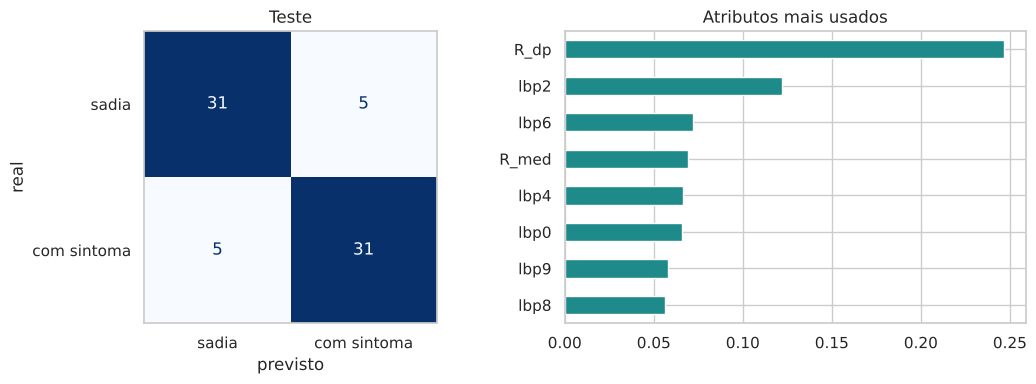

In [36]:

def atributos(im, fm):
    """Resume uma imagem em 16 números: cor (6) e textura LBP (10)."""
    pixels = im[fm]                                                      # só os pixels da folha (sem o fundo)
    cor = list(pixels.mean(axis=0)) + list(pixels.std(axis=0))           # média e desvio de R, G e B
    cinza = im.mean(axis=2)                                              # versão em tons de cinza
    lbp = local_binary_pattern((cinza * 255).astype(np.uint8), P=8, R=1, method="uniform")   # textura local
    hist = np.bincount(lbp[fm].astype(int), minlength=10)[:10] / fm.sum()                     # histograma normalizado do LBP
    return cor + list(hist)

nomes = ["R_med", "G_med", "B_med", "R_dp", "G_dp", "B_dp"] + ["lbp%d" % k for k in range(10)]
Xim = pd.DataFrame([atributos(im, fm) for im, fm in zip(imgs, formas)], columns=nomes)   # tabela: 1 linha por imagem
print(Xim.shape, "(imagens x atributos)")
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xim, rotulos_img, test_size=0.3, stratify=rotulos_img, random_state=SEED)

rf_im = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(Xi_tr, yi_tr)     # treina o classificador
pred_im = rf_im.predict(Xi_te)                                                            # prevê no teste
print("Acurácia: %.2f | sensibilidade (sintoma achado): %.2f | especificidade: %.2f" % (
      accuracy_score(yi_te, pred_im), recall_score(yi_te, pred_im), recall_score(yi_te, pred_im, pos_label=0)))
print("Precisão (alertas certos): %.2f | F1: %.2f" % (precision_score(yi_te, pred_im), f1_score(yi_te, pred_im)))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
matriz(yi_te, pred_im, axes[0], [0, 1], ["sadia", "com sintoma"], titulo="Teste")        # matriz de confusão
pd.Series(rf_im.feature_importances_, index=nomes).sort_values().tail(8).plot(kind="barh", color=TEAL, ax=axes[1], title="Atributos mais usados")
plt.tight_layout(); plt.show()


**Leitura dos gráficos**

- **Matriz "Teste":** linhas = realidade, colunas = previsão. De 36 folhas sadias, **31** foram certas e **5** receberam o alarme sem precisar; de 36 com sintoma, **31** foram achadas e **5** passaram despercebidas. Acurácia, sensibilidade e especificidade de **0,86**.
- **Gráfico "Atributos mais usados":** cada barra é a importância do atributo na decisão. O mais usado é **R_dp** (desvio-padrão do canal vermelho): mede o quanto a cor **varia** dentro da folha, ou seja, a irregularidade das manchas. Os atributos **lbp** descrevem a **textura** (padrões locais da imagem). Resumo: o modelo separa as folhas pela **variação de cor e pela textura**.


**Cuidados (muito importantes com imagens)**
- Folhas **sintéticas** são fáceis: com fotos reais, luz, fundo, câmera e variedade da planta pesam muito. Valide em **fotos de outro dia, outra fazenda, outro celular**.
- Sintomas parecidos (deficiência nutricional, outras doenças) confundem. O modelo é **triagem**, não diagnóstico: a confirmação é por análise de laboratório.
- Para imagens reais, a abordagem moderna usa **redes neurais convolucionais** (aprendem os atributos sozinhas).

**Experimente sem programar: Teachable Machine.** Abra <https://teachablemachine.withgoogle.com/>, escolha **Projeto de imagem**, crie duas classes (ex.: "folha sadia" e "folha com sintoma"), grave ou envie 30 a 50 fotos de cada, clique em **Treinar** e teste com uma foto nova pela câmera. É exatamente o fluxo do notebook, sem código.



---
## Bônus B (extra): do modelo à ação, enviar o alerta para o n8n
Apostila: **capítulo 14**.



### Bônus B · Alerta do Isolation Forest para o n8n
| | |
|---|---|
| **Problema** | Transformar a previsão em **ação**: quando o modelo sinaliza uma anomalia, avisar alguém. |
| **Dados** | A primeira anomalia detectada na seção 3.5 (variável `ev`). |
| **Modelo / técnica** | Nenhum modelo novo: montamos um **JSON** e o enviamos por **HTTP POST** a um *webhook* do **n8n** (automação visual). |
| **Como medimos** | O n8n responde com o código 200 quando recebe. |
| **O que observar** | Em branco, o código só **mostra** o JSON que seria enviado. Para enviar de verdade, cole a URL do webhook (precisa ser **pública**: n8n Cloud ou ngrok). |
| **Nos slides** | extra: não está nos slides |
| **Na apostila** | cap. 14 (monte o fluxo no n8n) |


In [37]:

import json, datetime                       # json: montar a mensagem; datetime: data e hora do alerta
try:
    import requests                         # requests: envia a mensagem pela internet (HTTP)
except ImportError:
    requests = None

N8N_WEBHOOK_URL = ""    # cole aqui a URL do webhook do n8n, ex.: "https://SEU-N8N/webhook-test/alerta-motor" (nunca publique chaves!)

def enviar_alerta(hora, vibracao, motor_id="M-017"):
    """Monta o JSON do alerta e, se houver URL, envia ao n8n."""
    payload = {"timestamp": datetime.datetime.now().isoformat(timespec="seconds"),   # quando
               "motor_id": motor_id, "hora_operacao": int(hora),                       # qual motor e hora
               "vibracao_mm_s": round(float(vibracao), 2), "nivel": "ALTO"}           # leitura e nível do alerta
    print(json.dumps(payload, indent=2, ensure_ascii=False))                          # mostra o JSON
    if N8N_WEBHOOK_URL and requests is not None:                                      # só envia se houver URL
        try:
            r = requests.post(N8N_WEBHOOK_URL, json=payload, timeout=10); print("n8n respondeu:", r.status_code)
        except Exception as e:
            print("Não foi possível chamar o n8n:", e)

primeira = ev.iloc[0]                                          # primeira anomalia detectada (seção 3.5)
enviar_alerta(primeira["hora"], primeira["vibracao"])


{
  "timestamp": "2026-10-29T12:59:48",
  "motor_id": "M-017",
  "hora_operacao": 18,
  "vibracao_mm_s": 1.84,
  "nivel": "ALTO"
}



---
## Bônus C (extra): redes neurais, o primeiro passo do Deep Learning
Apostila: **capítulo 3, seção 3.1**. Slides: **22** (o que é Deep Learning) e **27 a 32** (o Teachable Machine usa uma rede neural profunda).



### Bônus C · Rede neural pequena para prever a resistência do concreto
| | |
|---|---|
| **Problema** | Prever a **resistência do concreto (MPa)** com uma **rede neural** e comparar com a regressão linear e o Random Forest do exercício 1.3. |
| **Dados** | As mesmas 600 amostras do Bloco 1 (cimento, água, aditivo e idade), com a mesma divisão treino/teste. |
| **Modelo / técnica** | **Rede neural (MLP)** com 2 camadas escondidas (32 e 16 neurônios). Cada neurônio soma as entradas com pesos e aplica uma função; as camadas empilhadas aprendem relações curvas. **Deep Learning** é esta ideia com **muitas camadas**. |
| **Como medimos** | MAE, RMSE e R² no teste, e o gráfico real x previsto. |
| **O que observar** | A rede neural teve o menor erro nestes dados (MAE 1,87 MPa contra 2,16 do Random Forest), mas a diferença é pequena e ela é mais difícil de explicar. O Deep Learning brilha mesmo em **imagens, áudio e texto** com muitos exemplos. |
| **Nos slides** | 22 e 27 a 32 |
| **Na apostila** | cap. 3, seção 3.1 |


Arquitetura: 4 entradas -> 32 neurônios -> 16 neurônios -> 1 saída (resistência)
Pesos aprendidos: 705 (a regressão linear aprendeu só 5: α e quatro β)


,MAE (MPa),RMSE (MPa),R²
Modelo,,,
Regressão linear,5.526,6.567,0.767
Random Forest,2.160,2.669,0.962
Rede neural (MLP),1.869,2.265,0.972


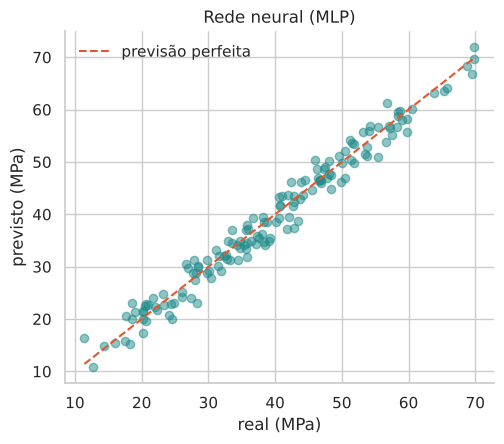

In [38]:

from sklearn.neural_network import MLPRegressor          # rede neural do scikit-learn (Perceptron de Múltiplas Camadas)
from sklearn.metrics import mean_squared_error           # erro quadrático médio (para o RMSE)

# --- 1) Refazer a mesma divisão treino/teste do exercício 1.3 e treinar a rede ---
X_tr, X_te, y_tr, y_te = train_test_split(civil[feats_civil], civil["resistencia_MPa"], test_size=0.25, random_state=SEED)
rede = make_pipeline(StandardScaler(),                   # redes neurais precisam das variáveis padronizadas
                     MLPRegressor(hidden_layer_sizes=(32, 16),   # 2 camadas escondidas: 32 e 16 neurônios
                                  max_iter=3000, random_state=SEED))
rede.fit(X_tr, y_tr)                                     # TREINAR: ajusta os pesos para errar menos
prev_rede = rede.predict(X_te)                           # previsões nos dados de teste

# --- 2) Quantos pesos a rede aprendeu? ---
mlp = rede[-1]                                           # o passo final do pipeline: a rede neural
n_pesos = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)   # pesos + vieses
print("Arquitetura: 4 entradas -> 32 neurônios -> 16 neurônios -> 1 saída (resistência)")
print("Pesos aprendidos: %d (a regressão linear aprendeu só 5: α e quatro β)" % n_pesos)

# --- 3) Métricas no teste, lado a lado com os modelos do exercício 1.3 ---
mae_r = mean_absolute_error(y_te, prev_rede); rmse_r = np.sqrt(mean_squared_error(y_te, prev_rede)); r2_r = r2_score(y_te, prev_rede)
tab = tab_civil[["MAE (MPa)", "RMSE (MPa)", "R²"]].copy()                  # tabela do exercício 1.3 (linear e Random Forest)
tab.loc["Rede neural (MLP)"] = [round(mae_r, 3), round(rmse_r, 3), round(r2_r, 3)]
display(tab)

# --- 4) Gráfico: real x previsto ---
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.scatter(y_te, prev_rede, alpha=0.5, color=TEAL)                         # cada ponto é uma amostra de teste
lim = [y_te.min(), y_te.max()]
ax.plot(lim, lim, "--", color=RED, label="previsão perfeita")              # linha ideal: previsto = real
ax.set_xlabel("real (MPa)"); ax.set_ylabel("previsto (MPa)"); ax.set_title("Rede neural (MLP)"); ax.legend(frameon=False); limpa(ax)
plt.tight_layout(); plt.show()


**Leitura do gráfico e da tabela**

- **O que a rede aprendeu:** 4 entradas (cimento, água, aditivo, idade), duas camadas escondidas (32 e 16 neurônios) e 1 saída (a resistência em MPa). No total são **705 pesos** ajustados no treino, contra apenas 5 números da regressão linear.
- **Tabela (teste):** a regressão linear erra **5,53 MPa** (R² 0,767), o Random Forest **2,16 MPa** (R² 0,962) e a rede neural **1,87 MPa** (R² 0,972). A rede neural teve o menor erro, mas a diferença para o Random Forest é pequena.
- **Gráfico "real x previsto":** horizontal = resistência real (MPa), vertical = prevista pela rede. A linha tracejada é a previsão perfeita; os pontos ficam **colados nela**, ou seja, a rede capturou as curvas (idade que satura, efeito da água).
- **Onde está o Deep Learning:** uma rede neural com **muitas** camadas (dezenas ou centenas) é o que se chama de *Deep Learning*. Ela compensa quando há muitos dados brutos, como **imagens** (defeitos em peças, folhas), **sinais** e **texto**. O Teachable Machine do Bônus A usa uma rede profunda já treinada.


**Perguntas**
1. Qual a diferença entre uma rede neural e a regressão linear do exercício 1.3?
2. A rede neural foi melhor que o Random Forest? O que isso diz sobre quando usar Deep Learning?
<details><summary><b>Ver respostas comentadas</b> (tente responder antes de abrir)</summary>

**1.** A regressão linear aprende **5 números** (α e quatro β) e só desenha uma **reta** (ou plano). A rede neural aprende **centenas de pesos** em camadas empilhadas, e por isso consegue desenhar **curvas** e combinar variáveis (por exemplo, o efeito da idade que satura com o tempo).

**2.** Aqui a rede foi um pouco melhor (MAE **1,87 MPa** contra **2,16 MPa** do Random Forest, e R² 0,972 contra 0,962), mas a diferença é pequena. Em **dados em tabela e poucos exemplos** (600 amostras), o Random Forest costuma chegar perto com muito menos ajuste e é mais simples de explicar. O **Deep Learning** compensa quando há **muitos dados** e informação "bruta" difícil de resumir em colunas: **imagens** (defeitos em peças, folhas), **sinais** (áudio, vibração bruta) e **texto**. O Teachable Machine do Bônus A usa uma rede profunda já treinada com milhões de imagens.

</details>
